<h1><center>Supervised ML Regression Competition</center></h1>


<img align="center" src="https://compraracciones.com/wp-content/uploads/2021/04/insurance.jpg" style="height:200px" style="width:100px"/>

<hr style="border:2px solid pink"> </hr>

You have been assigned the task of building a model that will predict the insurance cost

You'll find the data in the csv file `insurance`


- target col: "charges"


<hr style="border:2px solid pink"> </hr>


**Guidelines:** 


- train_test_split
    - random state = 42
    - test size = 0.3


- The one who gets the highest r2-score on test data wins


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

sns.set_theme(style="whitegrid")

## 1. Initial Data Exploration

Let's start by loading our dataset and taking a first look at it.


In [2]:
df = pd.read_csv("insurance.csv")
print(df.shape)
df.head()

(1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,7725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


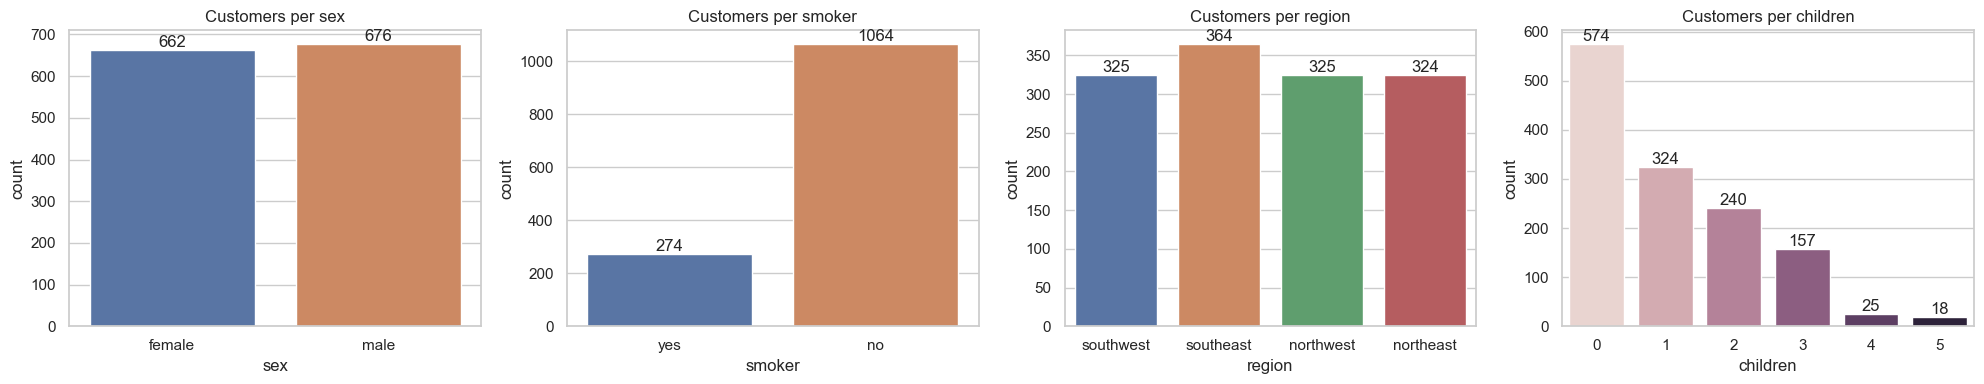

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

for ax, col in zip(axes, ["sex", "smoker", "region", "children"]):
    sns.countplot(data=df, x=col, hue=col, legend=False, ax=ax)
    ax.set_title(f"Customers per {col}")
    for container in ax.containers:
        ax.bar_label(container)

plt.tight_layout()
plt.show()

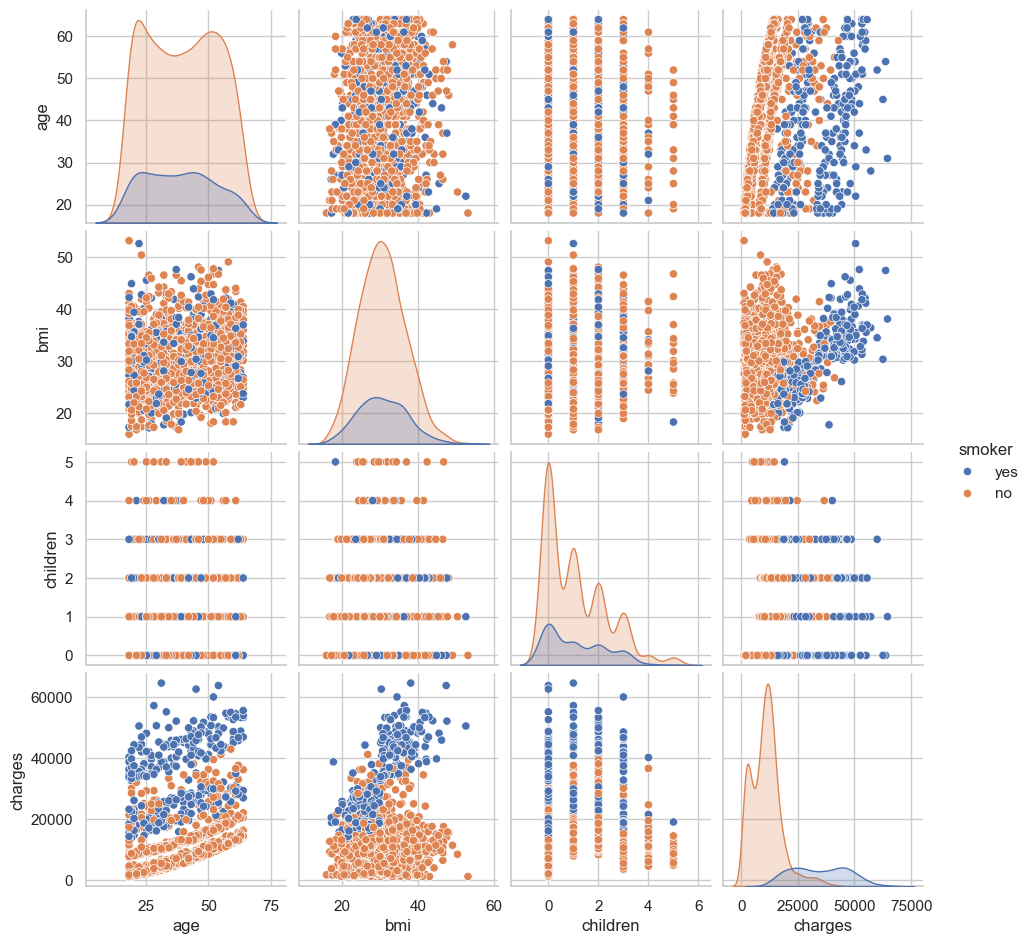

In [5]:
sns.pairplot(df, hue="smoker", diag_kind="kde", height=2.4)
plt.show()

## 2. Checking for Missing Values

It's important to know if our data has any missing values. Let's check that next.


In [6]:
print(df.isnull().sum())
print("Duplicated rows:", df.duplicated().sum())

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
Duplicated rows: 1


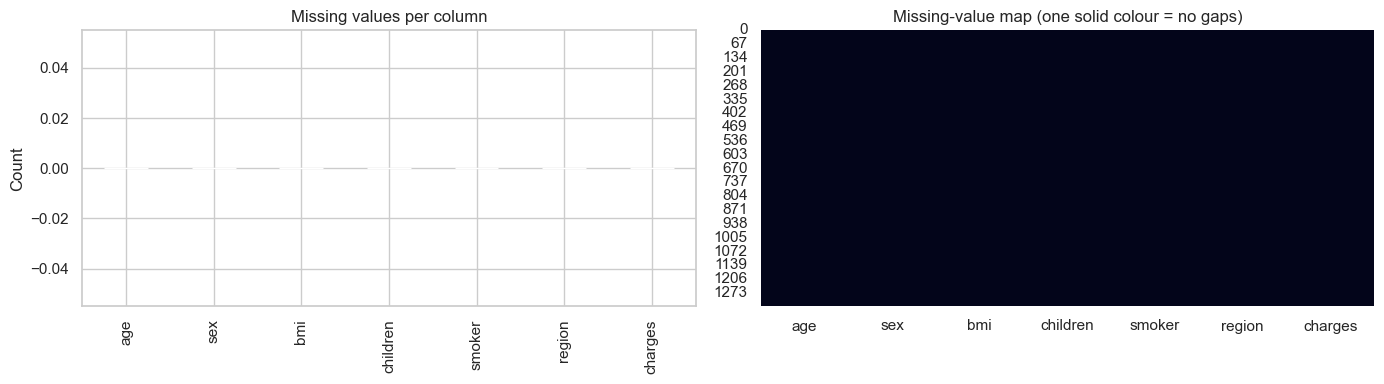

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

df.isnull().sum().plot(kind="bar", ax=axes[0], color=sns.color_palette("deep"))
axes[0].set_title("Missing values per column")
axes[0].set_ylabel("Count")

sns.heatmap(df.isnull(), cbar=False, ax=axes[1])
axes[1].set_title("Missing-value map (one solid colour = no gaps)")

plt.tight_layout()
plt.show()


## 3. Descriptive Statistics

Now, let's move on to some descriptive statistics.

Understanding the distribution of our data is crucial. Let's calculate some descriptive statistics.


In [8]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,15799.570247
std,14.049960,6.098187,1.205493,12559.984021
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,8106.480000
50%,39.000000,30.400000,1.000000,12403.585225
75%,51.000000,34.693750,2.000000,18948.612903
max,64.000000,53.130000,5.000000,64571.074480


In [9]:
df.describe(include="object")

,sex,smoker,region
count,1338,1338,1338
unique,2,2,4
top,male,no,southeast
freq,676,1064,364


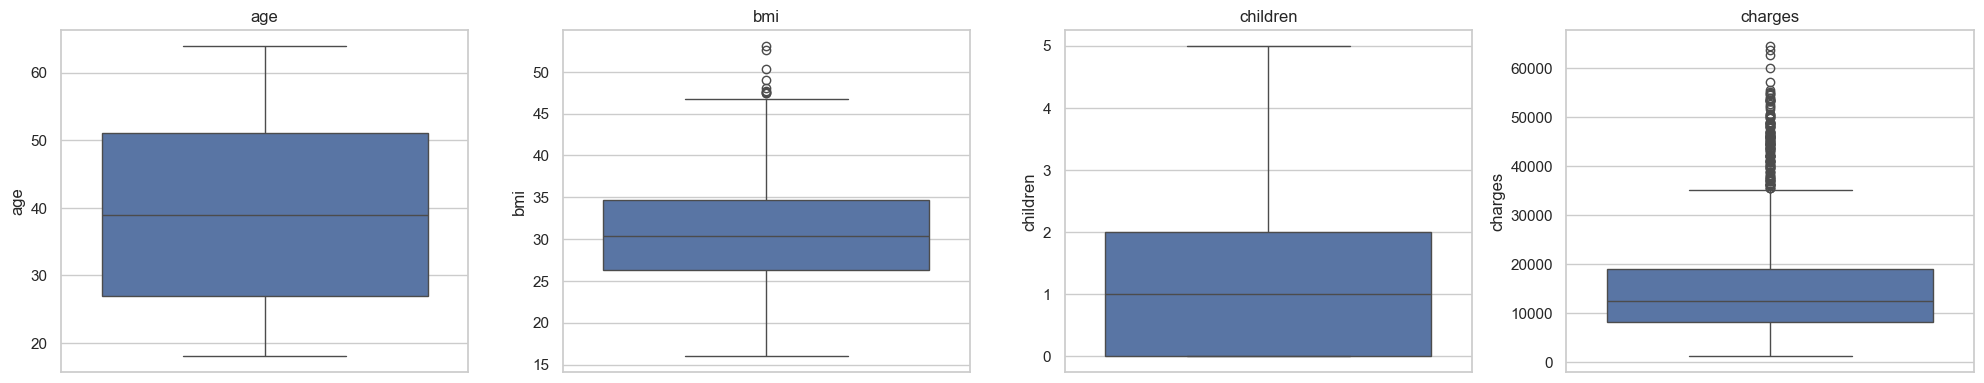

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

for ax, col in zip(axes, ["age", "bmi", "children", "charges"]):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

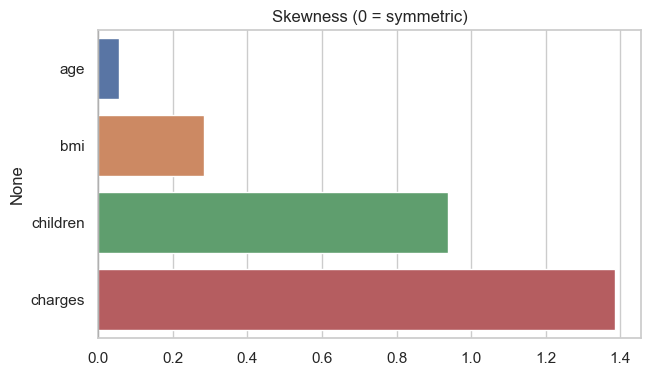

In [11]:
skew = df[["age", "bmi", "children", "charges"]].skew().sort_values()

plt.figure(figsize=(7, 4))
sns.barplot(x=skew.values, y=skew.index, hue=skew.index, legend=False)
plt.axvline(0, color="black")
plt.title("Skewness (0 = symmetric)")
plt.show()

## 4. Distribution Analysis

Visualizing the distributions of our features can provide valuable insights. Let's plot the distributions for 'age', 'bmi', and 'charges'.

### Task:
- Plot the histogram for 'age'
- Plot the histogram for 'bmi'
- Plot the histogram for 'charges'


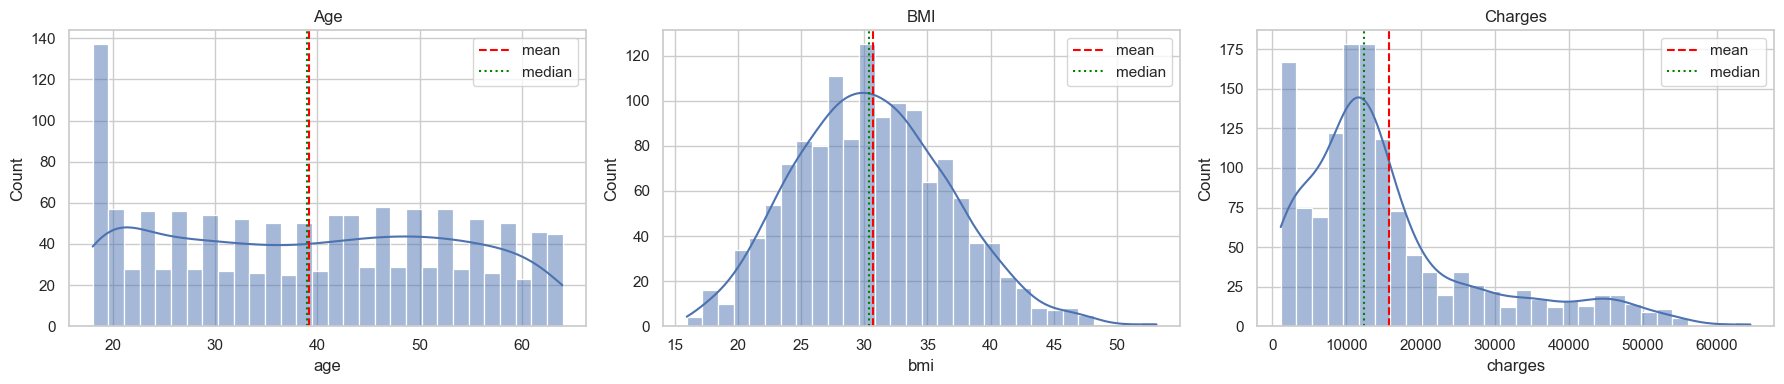

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

sns.histplot(df["age"], bins=30, kde=True, ax=axes[0])
axes[0].axvline(df["age"].mean(), color="red", linestyle="--", label="mean")
axes[0].axvline(df["age"].median(), color="green", linestyle=":", label="median")
axes[0].set_title("Age")
axes[0].legend()

sns.histplot(df["bmi"], bins=30, kde=True, ax=axes[1])
axes[1].axvline(df["bmi"].mean(), color="red", linestyle="--", label="mean")
axes[1].axvline(df["bmi"].median(), color="green", linestyle=":", label="median")
axes[1].set_title("BMI")
axes[1].legend()

sns.histplot(df["charges"], bins=30, kde=True, ax=axes[2])
axes[2].axvline(df["charges"].mean(), color="red", linestyle="--", label="mean")
axes[2].axvline(df["charges"].median(), color="green", linestyle=":", label="median")
axes[2].set_title("Charges")
axes[2].legend()

plt.tight_layout()
plt.show()

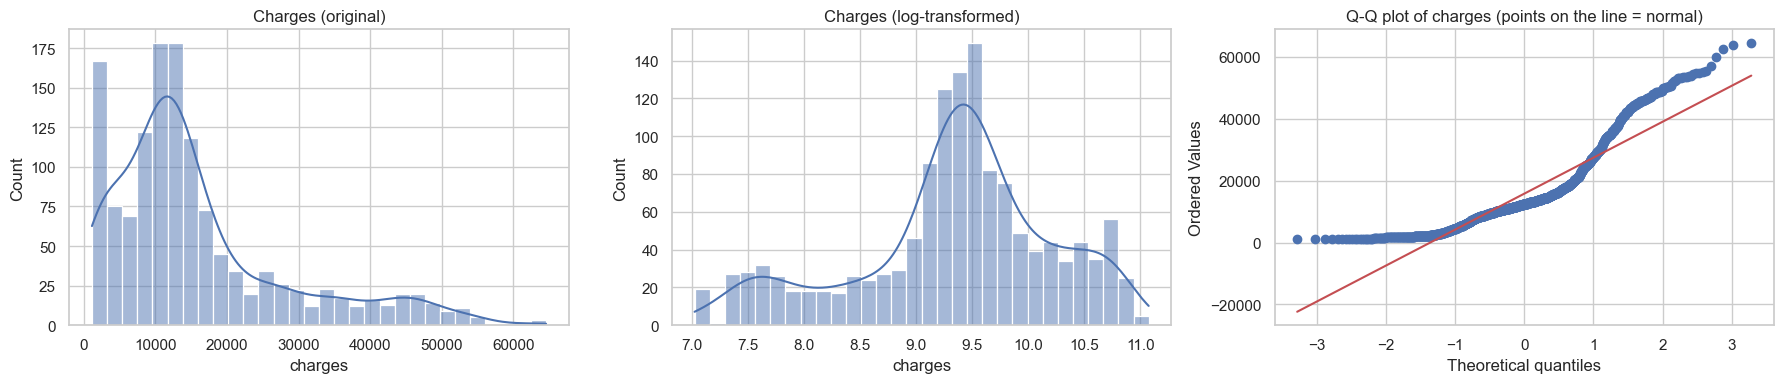

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

sns.histplot(df["charges"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Charges (original)")

sns.histplot(np.log1p(df["charges"]), bins=30, kde=True, ax=axes[1])
axes[1].set_title("Charges (log-transformed)")

stats.probplot(df["charges"], dist="norm", plot=axes[2])
axes[2].set_title("Q-Q plot of charges (points on the line = normal)")

plt.tight_layout()
plt.show()

## 5. Relationship Between Variables

Let's explore the relationship between some of our features and the target variable 'charges'. We'll create scatter plots to visualize these relationships.

### Task:
- Create a scatter plot for 'age' vs 'charges'
- Create a scatter plot for 'bmi' vs 'charges'
- Create a scatter plot for 'children' vs 'charges'


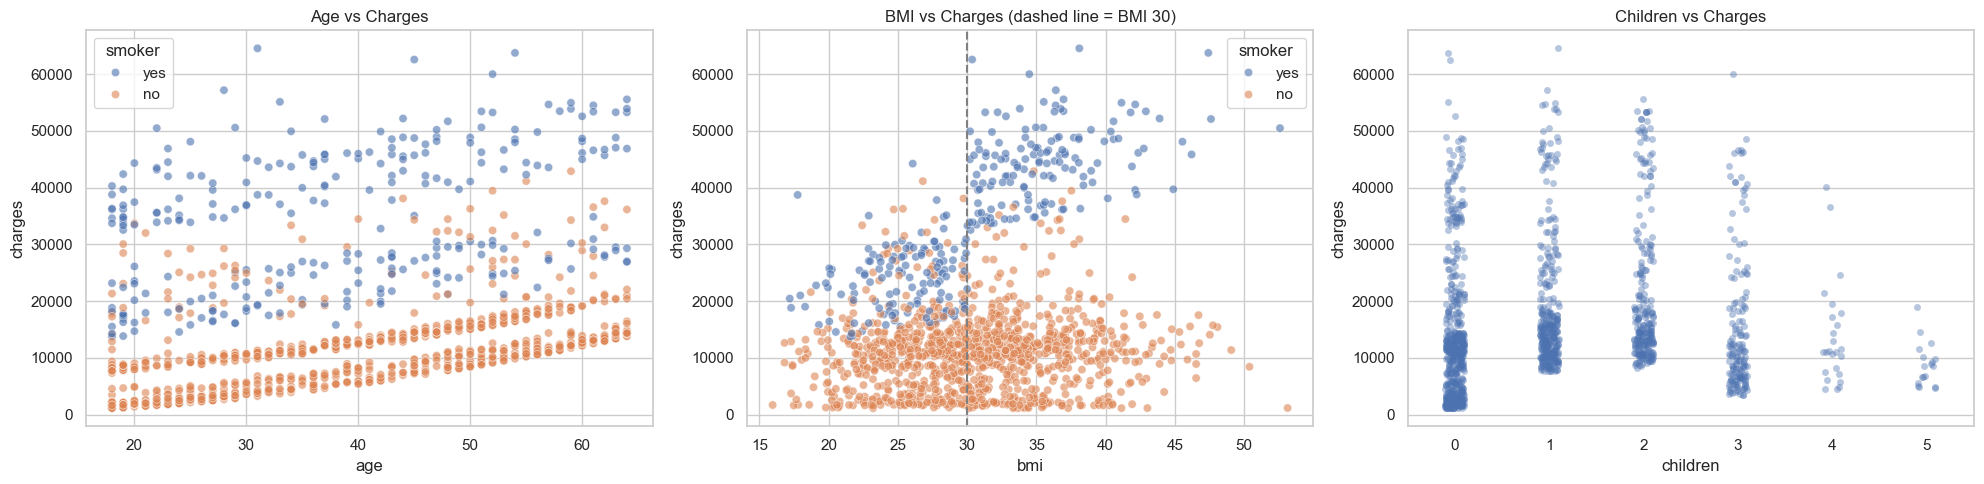

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

sns.scatterplot(data=df, x="age", y="charges", hue="smoker", alpha=0.6, ax=axes[0])
axes[0].set_title("Age vs Charges")

sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker", alpha=0.6, ax=axes[1])
axes[1].axvline(30, color="gray", linestyle="--")
axes[1].set_title("BMI vs Charges (dashed line = BMI 30)")

sns.stripplot(data=df, x="children", y="charges", alpha=0.4, ax=axes[2])
axes[2].set_title("Children vs Charges")

plt.tight_layout()
plt.show()

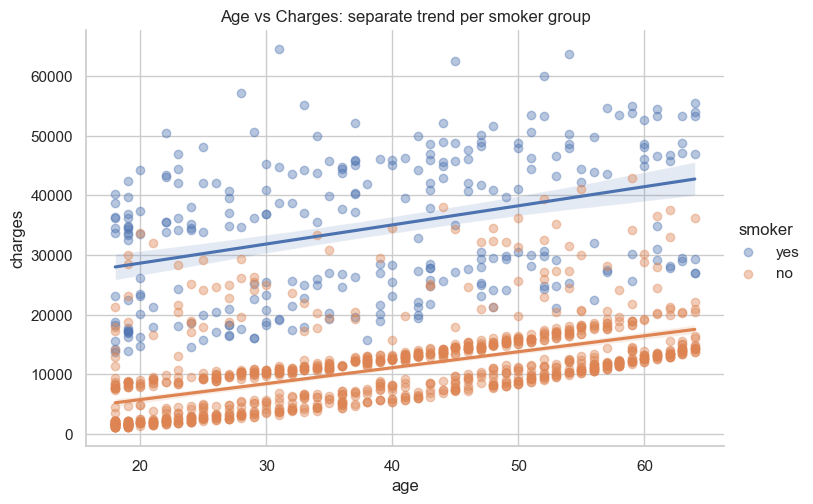

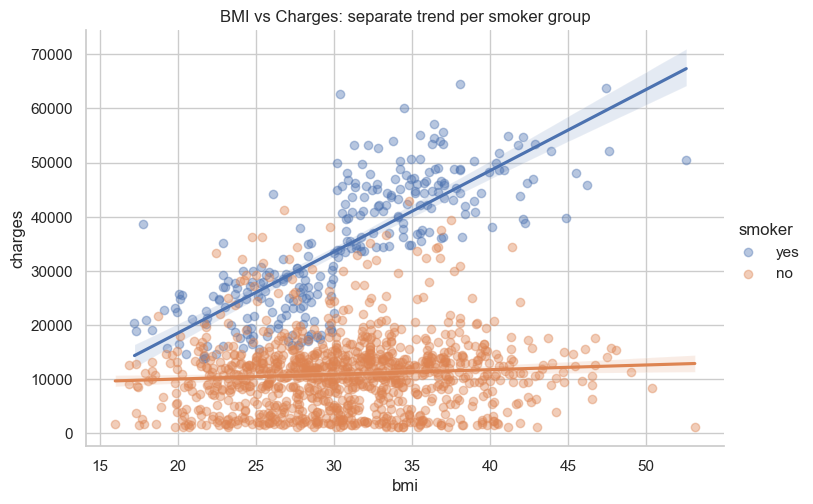

In [15]:
sns.lmplot(data=df, x="age", y="charges", hue="smoker",
           height=5, aspect=1.5, scatter_kws={"alpha": 0.4})
plt.title("Age vs Charges: separate trend per smoker group")
plt.show()

sns.lmplot(data=df, x="bmi", y="charges", hue="smoker",
           height=5, aspect=1.5, scatter_kws={"alpha": 0.4})
plt.title("BMI vs Charges: separate trend per smoker group")
plt.show()

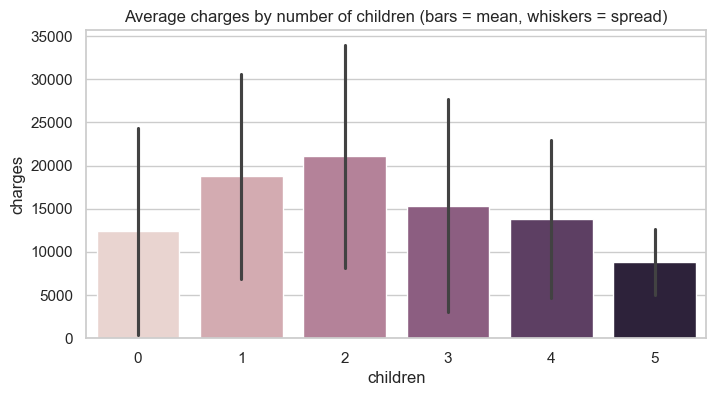

In [16]:
plt.figure(figsize=(8, 4))
sns.barplot(data=df, x="children", y="charges", hue="children", legend=False, errorbar="sd")
plt.title("Average charges by number of children (bars = mean, whiskers = spread)")
plt.show()

## 6. Categorical Analysis

Let's analyze the categorical features 'sex', 'smoker', and 'region' to see how they relate to 'charges'.

### Task:
- Plot the distribution of 'charges' for different 'sex'
- Plot the distribution of 'charges' for different 'smoker'
- Plot the distribution of 'charges' for different 'region'


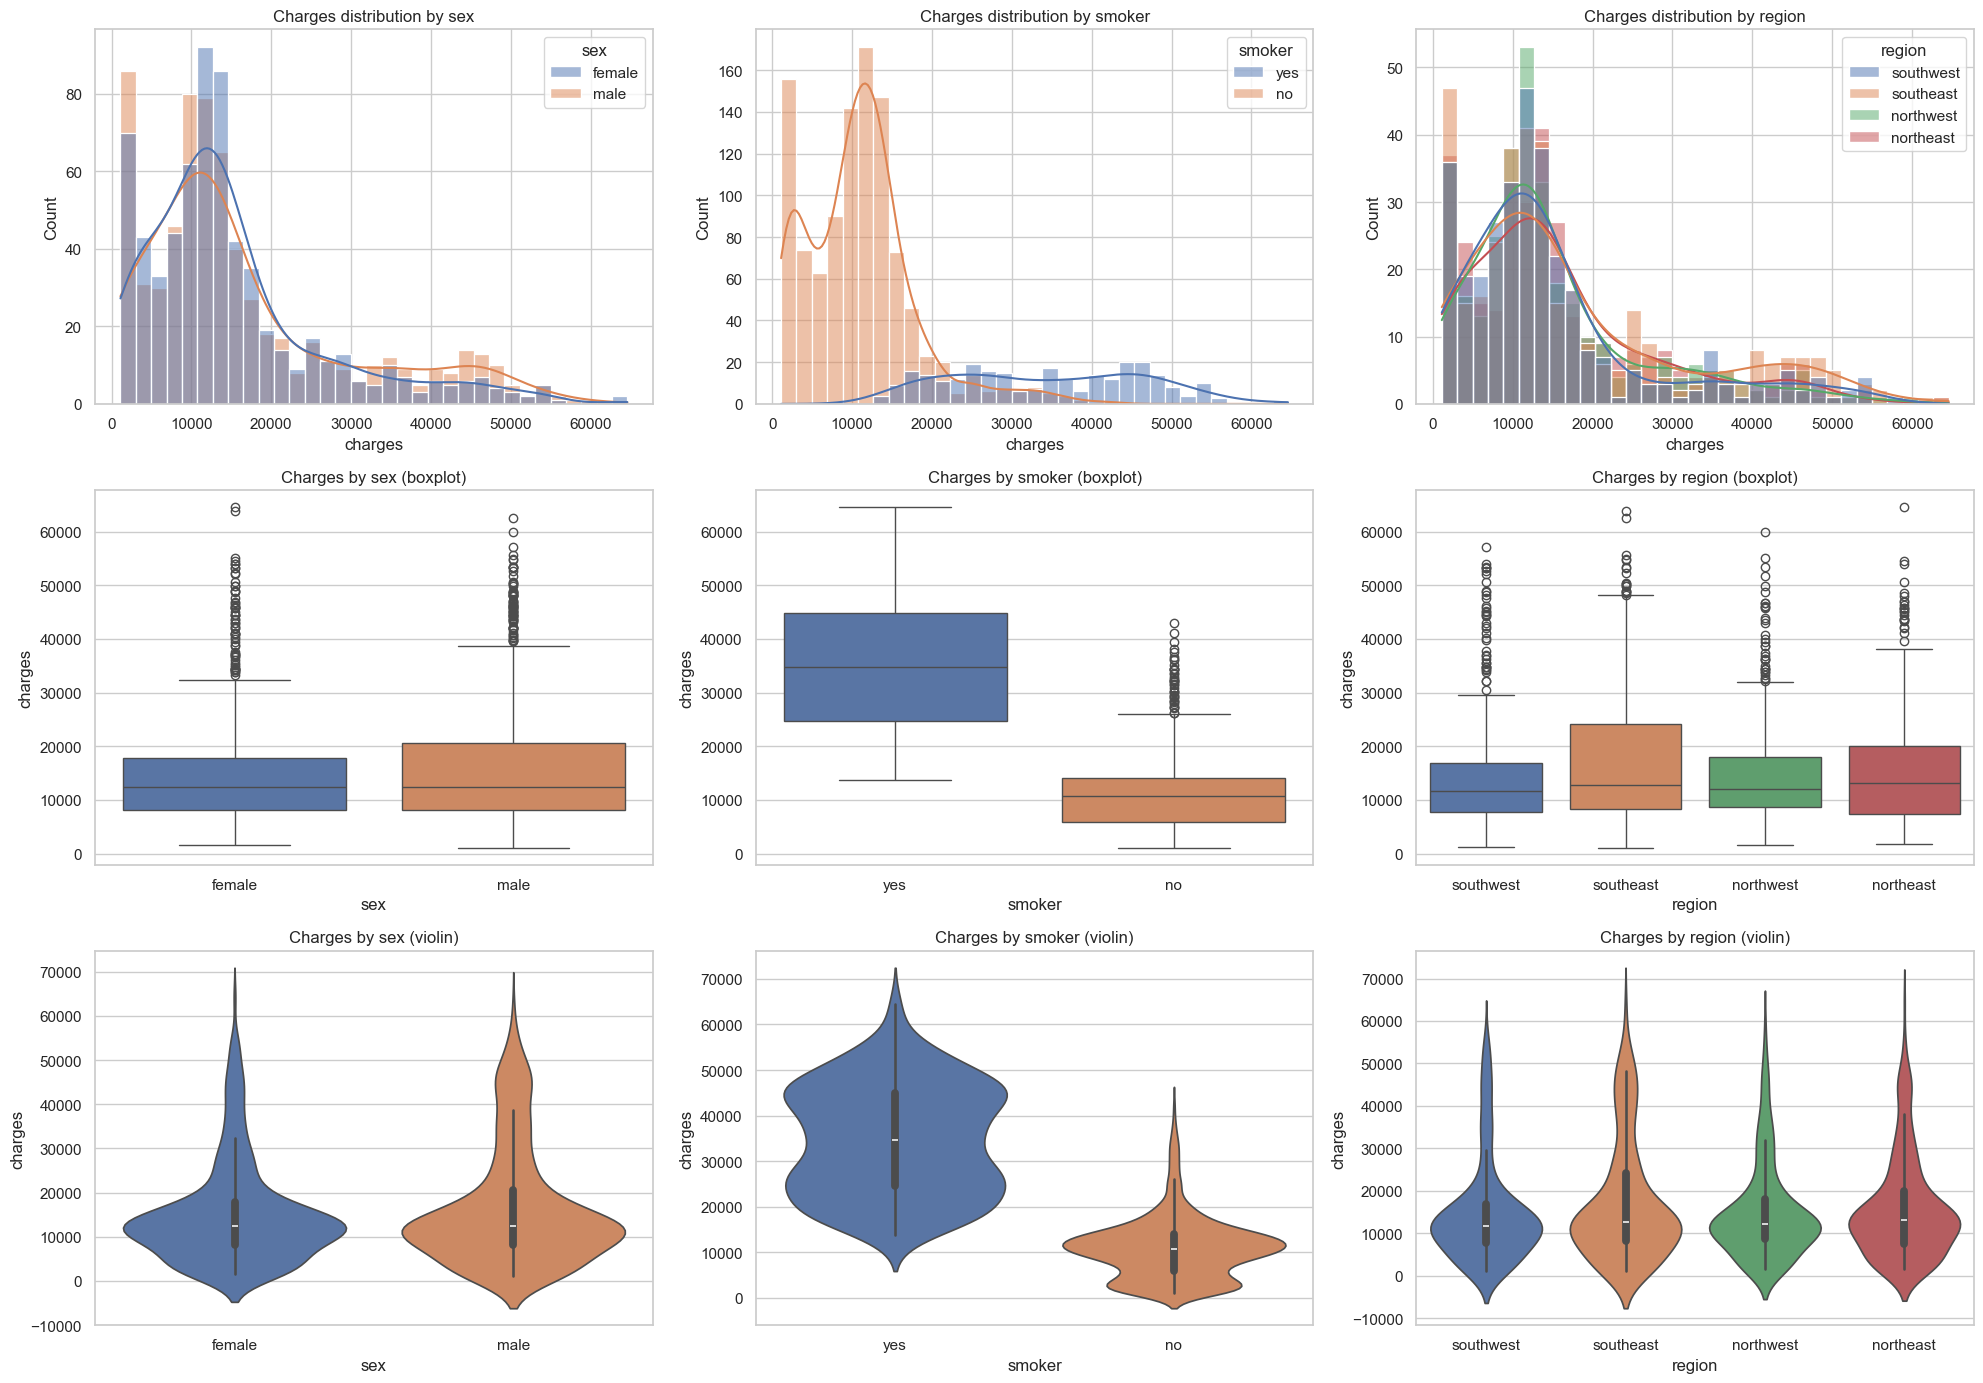

In [17]:
fig, axes = plt.subplots(3, 3, figsize=(20, 14))

for i, col in enumerate(["sex", "smoker", "region"]):
    sns.histplot(data=df, x="charges", hue=col, kde=True, ax=axes[0, i])
    axes[0, i].set_title(f"Charges distribution by {col}")

    sns.boxplot(data=df, x=col, y="charges", hue=col, legend=False, ax=axes[1, i])
    axes[1, i].set_title(f"Charges by {col} (boxplot)")

    sns.violinplot(data=df, x=col, y="charges", hue=col, legend=False, ax=axes[2, i])
    axes[2, i].set_title(f"Charges by {col} (violin)")

plt.tight_layout()
plt.show()

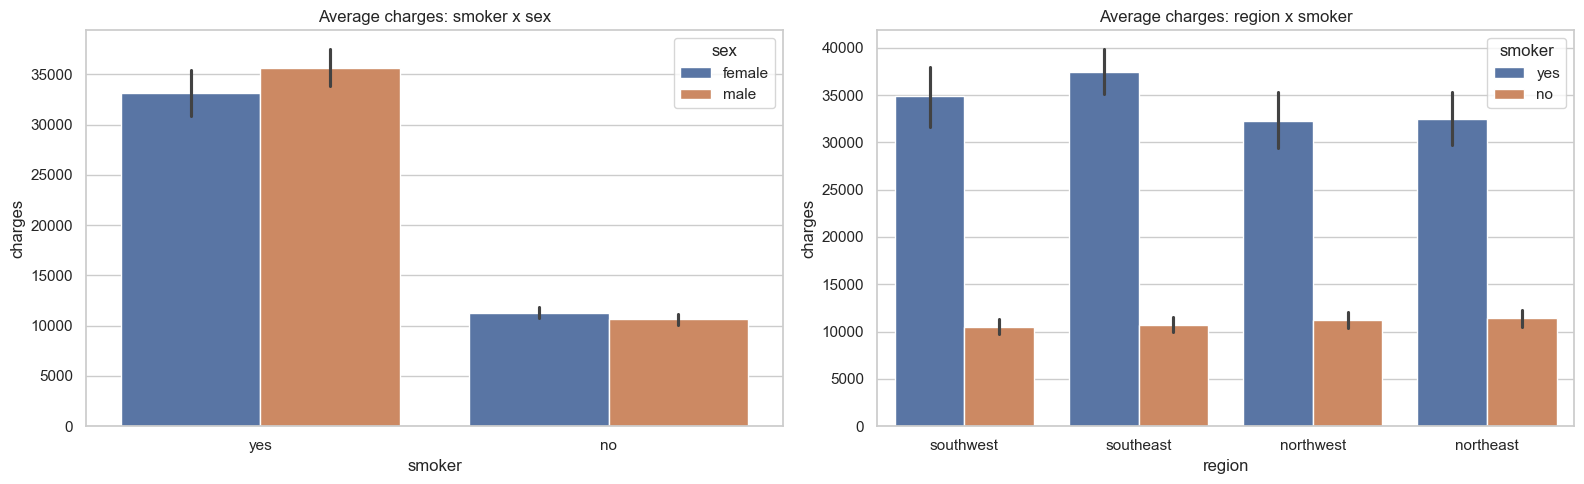

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(data=df, x="smoker", y="charges", hue="sex", ax=axes[0])
axes[0].set_title("Average charges: smoker x sex")

sns.barplot(data=df, x="region", y="charges", hue="smoker", ax=axes[1])
axes[1].set_title("Average charges: region x smoker")

plt.tight_layout()
plt.show()

## 7. Correlation Analysis

To understand how our numerical features relate to each other and to the target variable, let's calculate and visualize the correlation matrix.

### Task:
- Calculate the correlation matrix for the dataset
- Visualize the correlation matrix using a heatmap


In [19]:
df_corr = df.copy()
df_corr["smoker"] = (df_corr["smoker"] == "yes").astype(int)
df_corr["sex"] = (df_corr["sex"] == "male").astype(int)

corr = df_corr.drop(columns="region").corr()
corr

,age,sex,bmi,children,smoker,charges
age,1.000000,-0.020856,0.109272,0.042469,-0.025019,0.291786
sex,-0.020856,1.000000,0.046371,0.017163,0.076185,0.056703
bmi,0.109272,0.046371,1.000000,0.012759,0.003750,0.194897
children,0.042469,0.017163,0.012759,1.000000,0.007673,0.120829
smoker,-0.025019,0.076185,0.003750,0.007673,1.000000,0.759492
charges,0.291786,0.056703,0.194897,0.120829,0.759492,1.000000


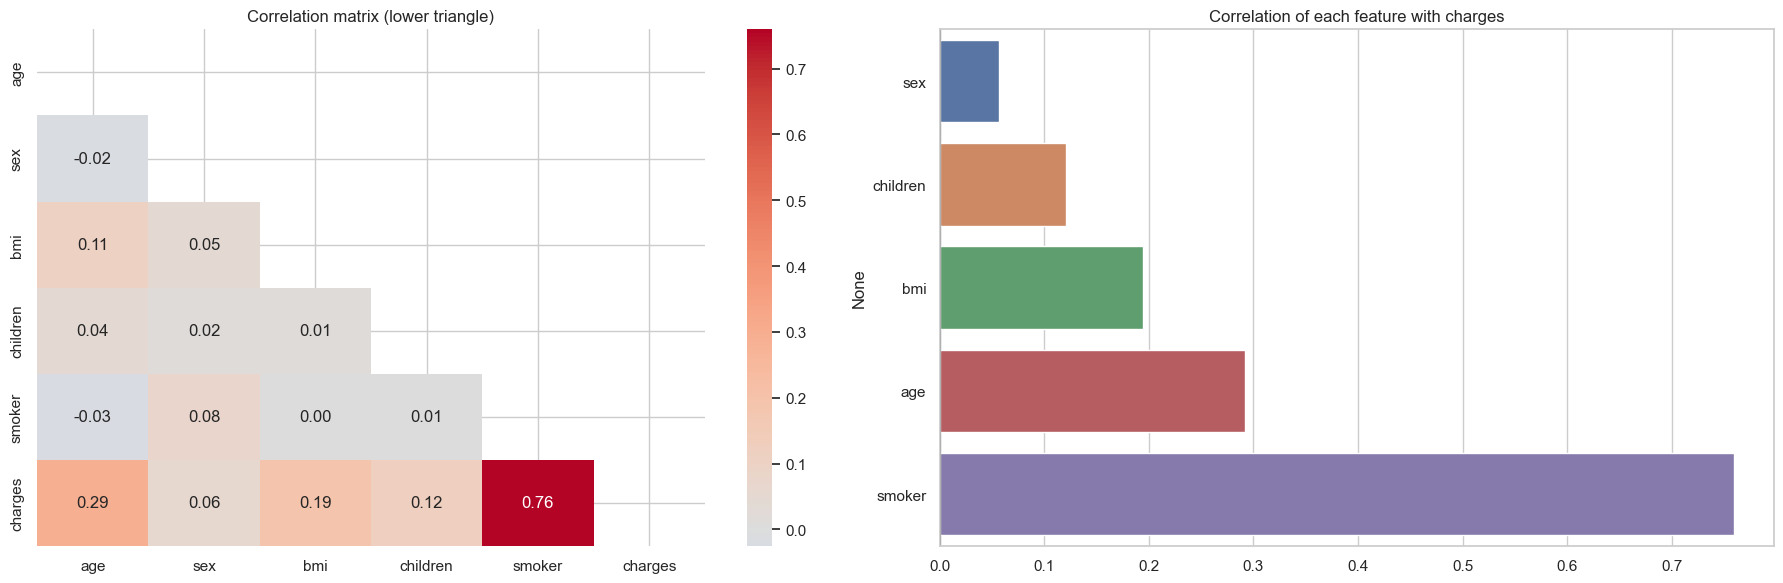

In [20]:
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Correlation matrix (lower triangle)")

corr_target = corr["charges"].drop("charges").sort_values()
sns.barplot(x=corr_target.values, y=corr_target.index, hue=corr_target.index,
            legend=False, ax=axes[1])
axes[1].axvline(0, color="black")
axes[1].set_title("Correlation of each feature with charges")

plt.tight_layout()
plt.show()

# Modelling time!

## 1. Find the Naive Baseline

Before we build any models, let's establish a naive baseline. This will help us understand how well our models perform compared to a simple approach. In regression problems, the naive baseline is often the mean of the target variable.

### Task:
- Calculate the mean of the target variable 'charges'
- Explain why it's important to establish a naive baseline


In [21]:
X = df.drop(columns="charges")
y = df["charges"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

print("Mean of all charges:", round(y.mean(), 2))
print("Mean of training charges:", round(y_train.mean(), 2))

Mean of all charges: 15799.57
Mean of training charges: 15891.98


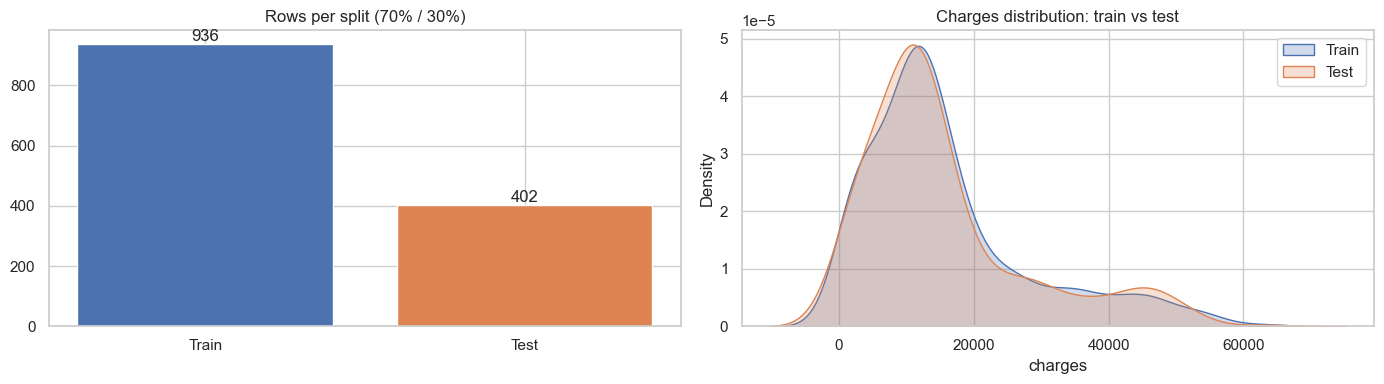

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].bar(["Train", "Test"], [len(X_train), len(X_test)], color=sns.color_palette("deep")[:2])
axes[0].set_title("Rows per split (70% / 30%)")
for i, v in enumerate([len(X_train), len(X_test)]):
    axes[0].text(i, v, str(v), ha="center", va="bottom")

sns.kdeplot(y_train, label="Train", fill=True, ax=axes[1])
sns.kdeplot(y_test, label="Test", fill=True, ax=axes[1])
axes[1].set_title("Charges distribution: train vs test")
axes[1].legend()

plt.tight_layout()
plt.show()

In [23]:
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
y_pred_base = baseline.predict(X_test)

base_r2 = r2_score(y_test, y_pred_base)
base_rmse = np.sqrt(mean_squared_error(y_test, y_pred_base))
base_mae = mean_absolute_error(y_test, y_pred_base)
print(f"Baseline  R2: {base_r2:.4f} | RMSE: {base_rmse:.2f} | MAE: {base_mae:.2f}")

Baseline  R2: -0.0006 | RMSE: 12541.03 | MAE: 9446.15


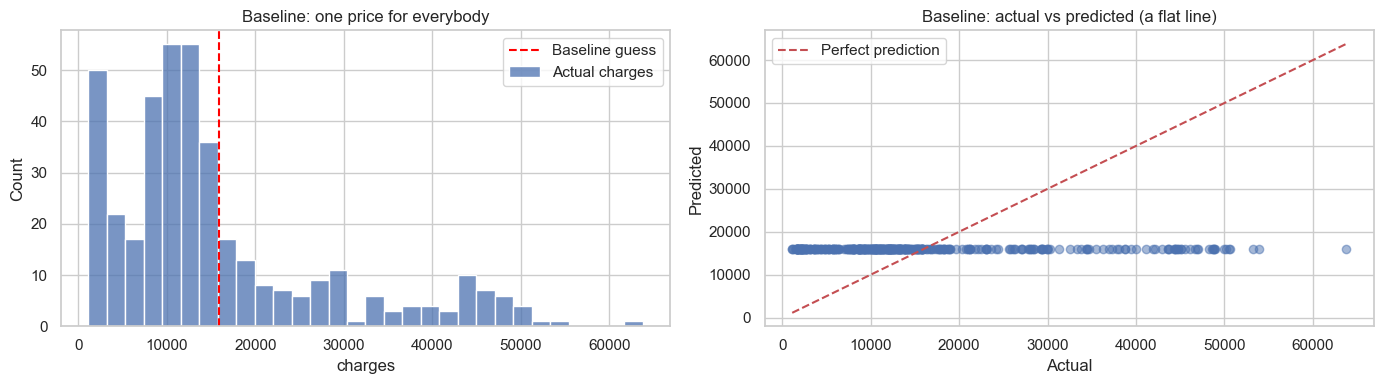

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(y_test, bins=30, ax=axes[0], label="Actual charges")
axes[0].axvline(y_train.mean(), color="red", linestyle="--", label="Baseline guess")
axes[0].legend()
axes[0].set_title("Baseline: one price for everybody")

axes[1].scatter(y_test, y_pred_base, alpha=0.5)
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", label="Perfect prediction")
axes[1].set_xlabel("Actual")
axes[1].set_ylabel("Predicted")
axes[1].set_title("Baseline: actual vs predicted (a flat line)")
axes[1].legend()

plt.tight_layout()
plt.show()

## 2. Initial Modelling Without GridSearch or Pipeline

Let's build a simple linear regression model without any feature engineering, grid search, or pipeline. This will serve as our initial baseline for comparison.

### Task:
- Split the data into training and test sets
- Train a simple linear regression model
- Evaluate its performance using regression metrics
- Write it down as a markdown below so you can keep track. This is a scientific experiment


In [25]:
X_enc = pd.get_dummies(X, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X_enc, y, test_size=0.3, random_state=42
)

lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

lr_r2 = r2_score(y_test, y_pred_lr)
lr_rmse = np.sqrt(mean_squared_error(y_test, y_pred_lr))
lr_mae = mean_absolute_error(y_test, y_pred_lr)
print(f"Linear Regression  R2: {lr_r2:.4f} | RMSE: {lr_rmse:.2f} | MAE: {lr_mae:.2f}")

Linear Regression  R2: 0.7263 | RMSE: 6558.51 | MAE: 4996.26


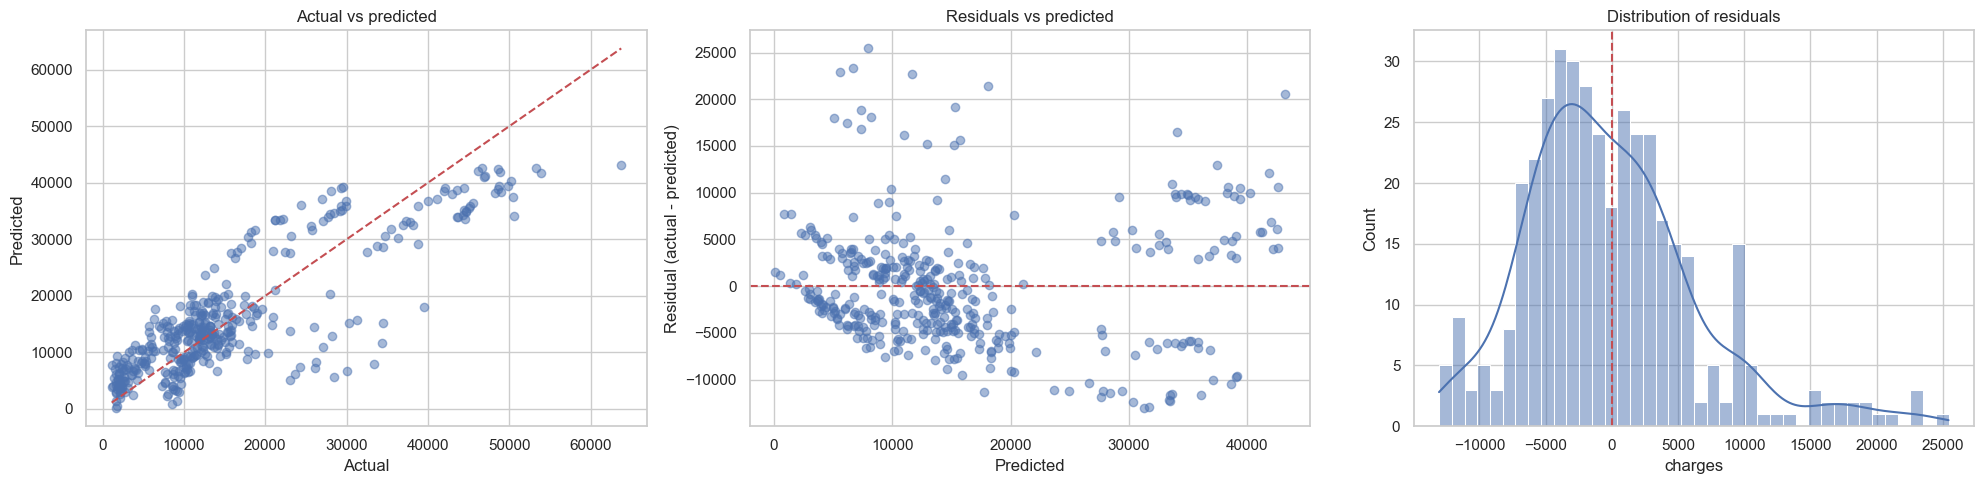

In [26]:
residuals_lr = y_test - y_pred_lr

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

axes[0].scatter(y_test, y_pred_lr, alpha=0.5)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
axes[0].set_xlabel("Actual")
axes[0].set_ylabel("Predicted")
axes[0].set_title("Actual vs predicted")

axes[1].scatter(y_pred_lr, residuals_lr, alpha=0.5)
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Residual (actual - predicted)")
axes[1].set_title("Residuals vs predicted")

sns.histplot(residuals_lr, bins=40, kde=True, ax=axes[2])
axes[2].axvline(0, color="r", linestyle="--")
axes[2].set_title("Distribution of residuals")

plt.tight_layout()
plt.show()

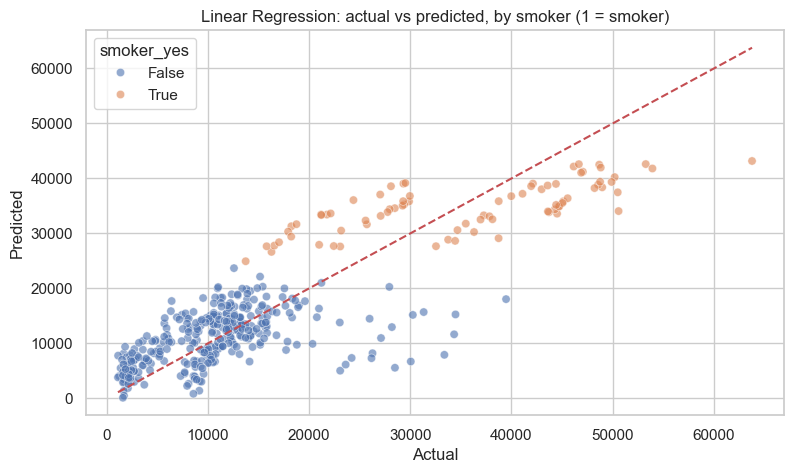

In [27]:
plt.figure(figsize=(9, 5))
sns.scatterplot(x=y_test, y=y_pred_lr, hue=X_test["smoker_yes"], alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Linear Regression: actual vs predicted, by smoker (1 = smoker)")
plt.show()

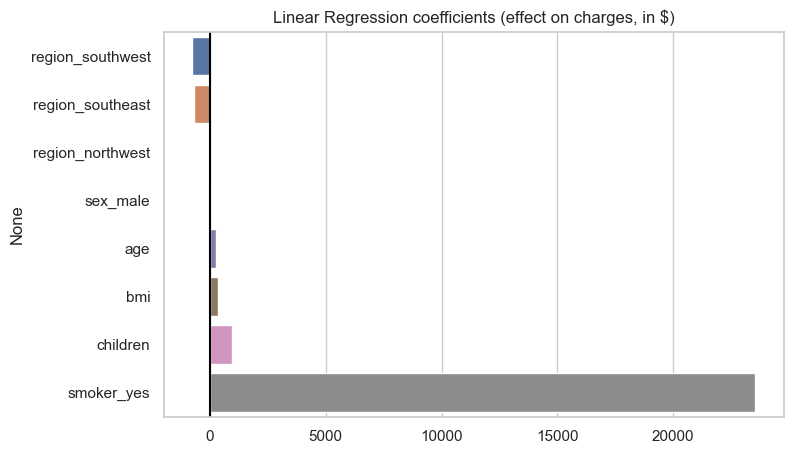

In [28]:
coefs_lr = pd.Series(lr.coef_, index=X_train.columns).sort_values()

plt.figure(figsize=(8, 5))
sns.barplot(x=coefs_lr.values, y=coefs_lr.index, hue=coefs_lr.index, legend=False)
plt.axvline(0, color="black")
plt.title("Linear Regression coefficients (effect on charges, in $)")
plt.show()

## 3. Feature Engineering

Now, let's brainstorm and create some new features to see if we can improve the model's performance.

### Questions:
1. Should we create an interaction feature between 'bmi' and 'children'? 
2. Should we create age groups to see if the model improves by categorizing age?
3. Should we create a high-risk indicator based on 'smoker' and 'bmi'?

- Remember nothing is set in stone, this is your experiment, your hypothesis. You may not need to, but its important to explore these questions

### Task:
- Create new features based on the questions above
- Explain the rationale behind each feature



In [29]:
df_fe = df.copy()

# Q1: interaction between bmi and children
df_fe["bmi_children"] = df_fe["bmi"] * df_fe["children"]

# Q2: age groups
df_fe["age_group"] = pd.cut(
    df_fe["age"],
    bins=[17, 29, 39, 49, 59, 100],
    labels=["18-29", "30-39", "40-49", "50-59", "60+"]
).astype(str)

# Q3: high-risk flag = smoker AND obese (BMI >= 30)
df_fe["high_risk"] = ((df_fe["smoker"] == "yes") & (df_fe["bmi"] >= 30)).astype(int)

df_fe[["age", "bmi", "children", "smoker", "bmi_children", "age_group", "high_risk"]].head()

,age,bmi,children,smoker,bmi_children,age_group,high_risk
0,19,27.900,0,yes,0.00,18-29,0
1,18,33.770,1,no,33.77,18-29,0
2,28,33.000,3,no,99.00,18-29,0
3,33,22.705,0,no,0.00,30-39,0
4,32,28.880,0,no,0.00,30-39,0


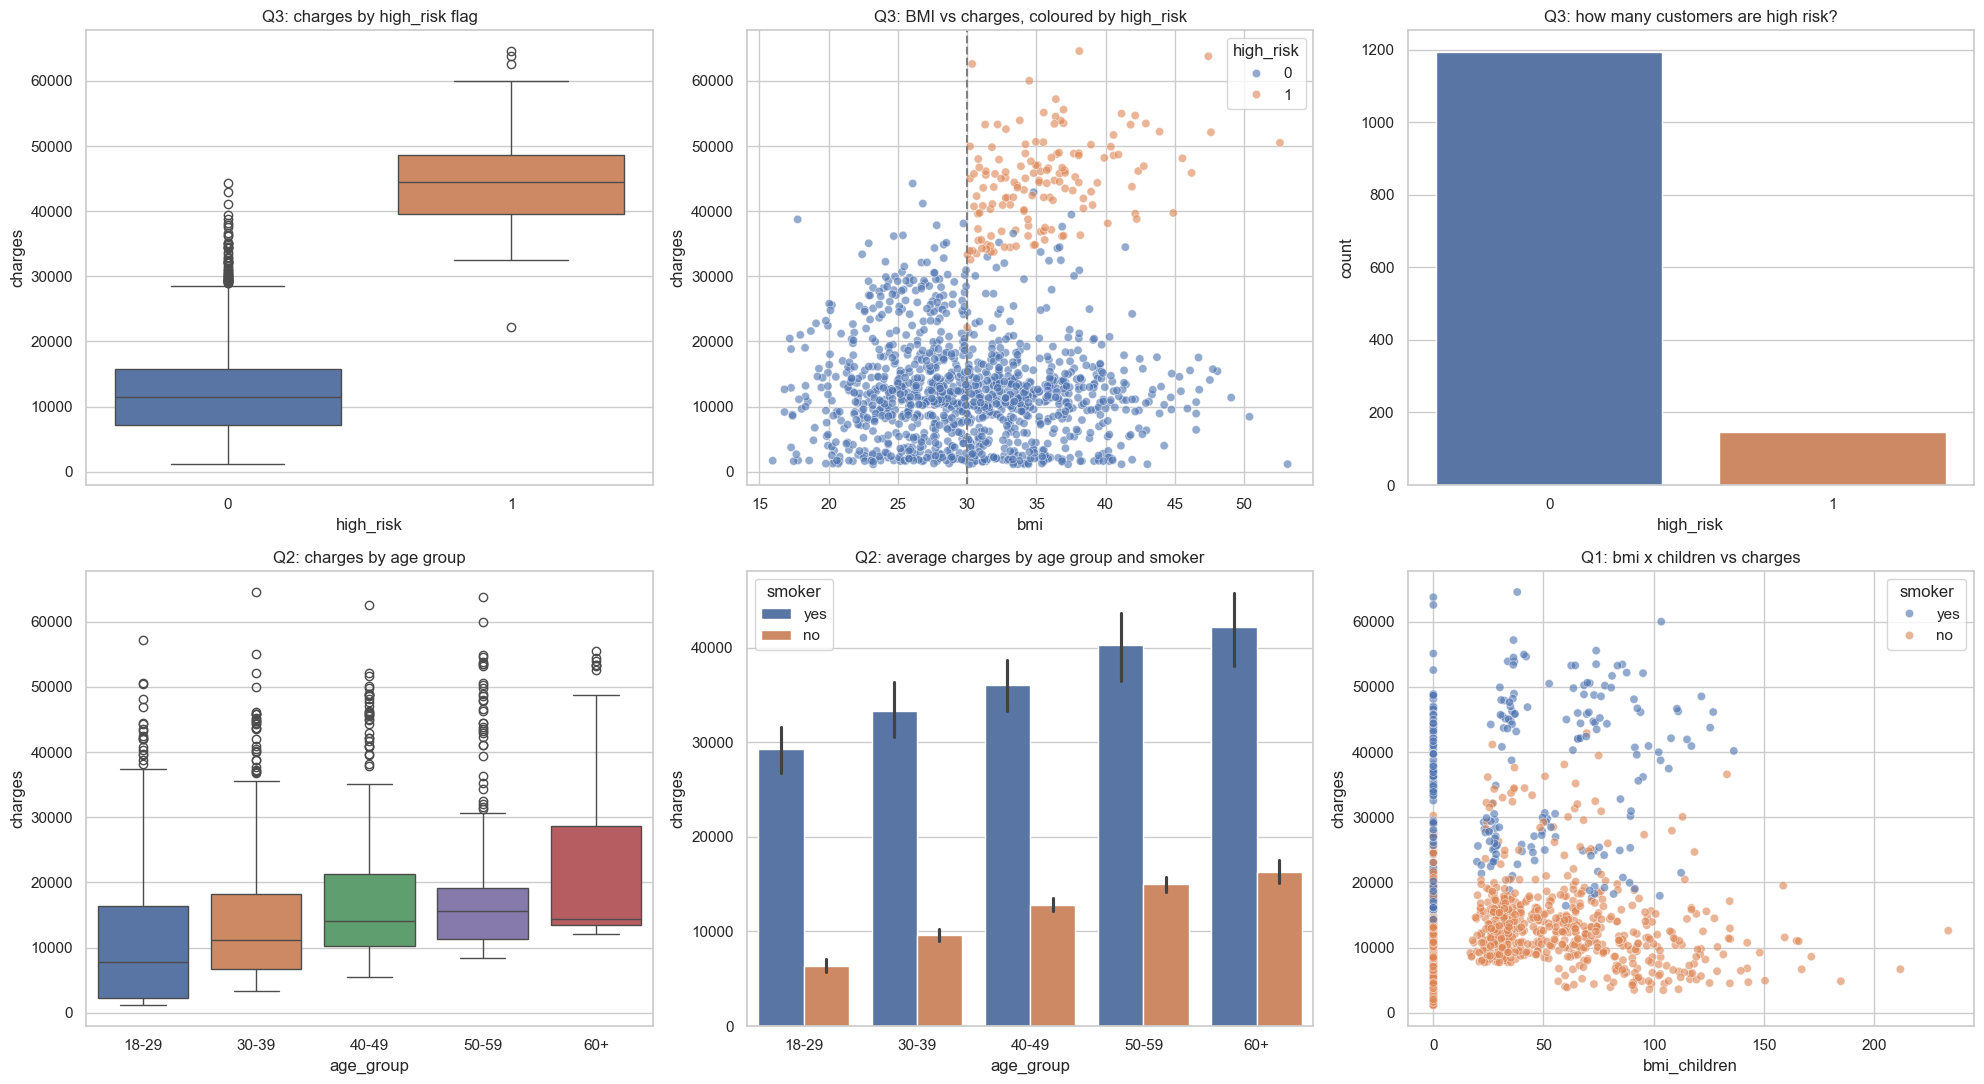

In [30]:
age_order = ["18-29", "30-39", "40-49", "50-59", "60+"]

fig, axes = plt.subplots(2, 3, figsize=(20, 11))

sns.boxplot(data=df_fe, x="high_risk", y="charges", hue="high_risk", legend=False, ax=axes[0, 0])
axes[0, 0].set_title("Q3: charges by high_risk flag")

sns.scatterplot(data=df_fe, x="bmi", y="charges", hue="high_risk", alpha=0.6, ax=axes[0, 1])
axes[0, 1].axvline(30, color="gray", linestyle="--")
axes[0, 1].set_title("Q3: BMI vs charges, coloured by high_risk")

sns.countplot(data=df_fe, x="high_risk", hue="high_risk", legend=False, ax=axes[0, 2])
axes[0, 2].set_title("Q3: how many customers are high risk?")

sns.boxplot(data=df_fe, x="age_group", y="charges", order=age_order,
            hue="age_group", legend=False, ax=axes[1, 0])
axes[1, 0].set_title("Q2: charges by age group")

sns.barplot(data=df_fe, x="age_group", y="charges", order=age_order, hue="smoker", ax=axes[1, 1])
axes[1, 1].set_title("Q2: average charges by age group and smoker")

sns.scatterplot(data=df_fe, x="bmi_children", y="charges", hue="smoker", alpha=0.6, ax=axes[1, 2])
axes[1, 2].set_title("Q1: bmi x children vs charges")

plt.tight_layout()
plt.show()

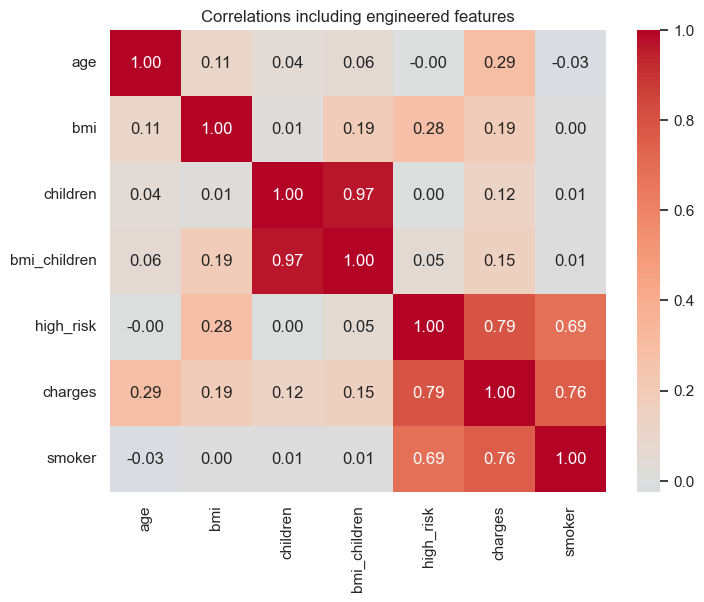

In [31]:
fe_corr = df_fe[["age", "bmi", "children", "bmi_children", "high_risk", "charges"]].copy()
fe_corr["smoker"] = (df_fe["smoker"] == "yes").astype(int)

plt.figure(figsize=(8, 6))
sns.heatmap(fe_corr.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlations including engineered features")
plt.show()

## 4. Modelling with Feature Engineering

Now that we have new features, let's see if they improve our model's performance.
Did it improve the performance? Yes? No? Why

### Task:
- Split the data into training and test sets
- Train a linear regression model with the new features
- Evaluate its performance using regression metrics


In [32]:
X_fe = pd.get_dummies(df_fe.drop(columns="charges"), drop_first=True)

X_train_fe, X_test_fe, y_train, y_test = train_test_split(
    X_fe, y, test_size=0.3, random_state=42
)

lr_fe = LinearRegression()
lr_fe.fit(X_train_fe, y_train)
y_pred_fe = lr_fe.predict(X_test_fe)

fe_r2 = r2_score(y_test, y_pred_fe)
fe_rmse = np.sqrt(mean_squared_error(y_test, y_pred_fe))
fe_mae = mean_absolute_error(y_test, y_pred_fe)

print(f"Linear (raw)       R2: {lr_r2:.4f} | RMSE: {lr_rmse:.2f}")
print(f"Linear (+features) R2: {fe_r2:.4f} | RMSE: {fe_rmse:.2f}")

Linear (raw)       R2: 0.7263 | RMSE: 6558.51
Linear (+features) R2: 0.8158 | RMSE: 5381.11


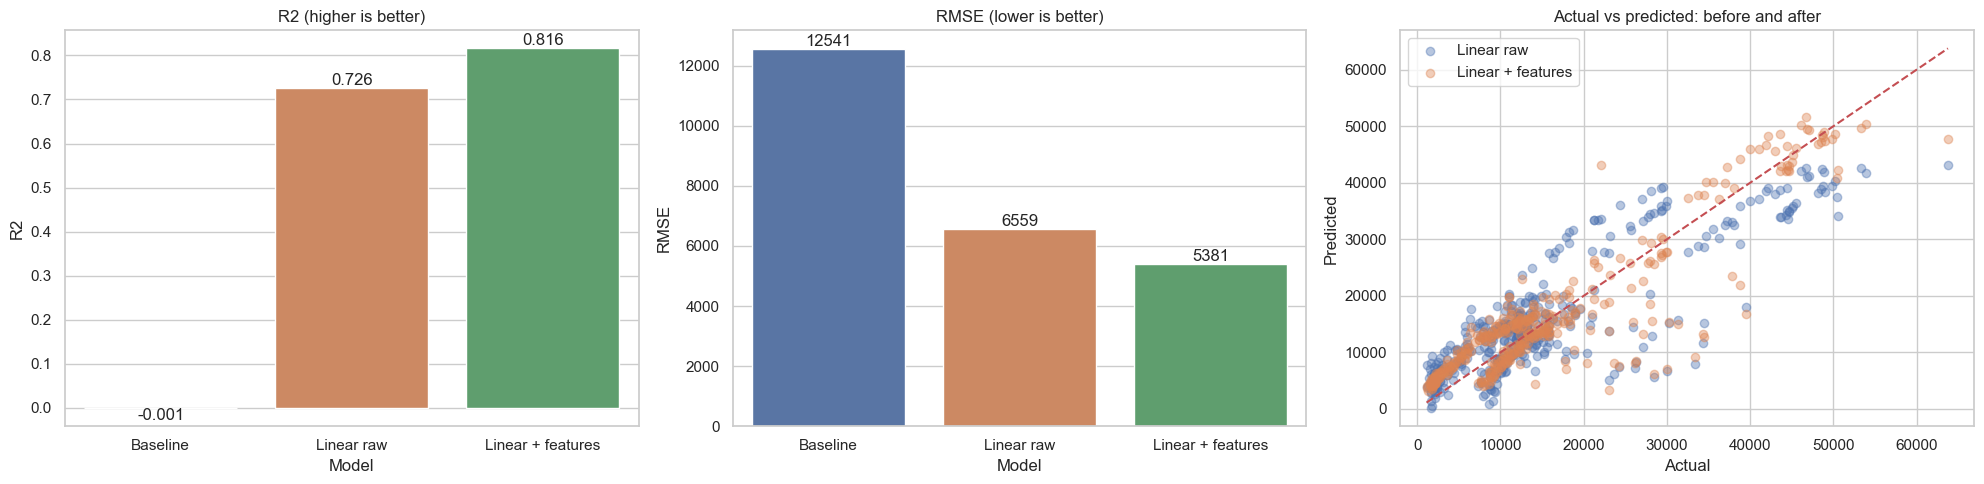

In [33]:
comp = pd.DataFrame({
    "Model": ["Baseline", "Linear raw", "Linear + features"],
    "R2": [base_r2, lr_r2, fe_r2],
    "RMSE": [base_rmse, lr_rmse, fe_rmse],
})

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

sns.barplot(data=comp, x="Model", y="R2", hue="Model", legend=False, ax=axes[0])
axes[0].set_title("R2 (higher is better)")
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%.3f")

sns.barplot(data=comp, x="Model", y="RMSE", hue="Model", legend=False, ax=axes[1])
axes[1].set_title("RMSE (lower is better)")
for c in axes[1].containers:
    axes[1].bar_label(c, fmt="%.0f")

axes[2].scatter(y_test, y_pred_lr, alpha=0.4, label="Linear raw")
axes[2].scatter(y_test, y_pred_fe, alpha=0.4, label="Linear + features")
axes[2].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
axes[2].set_xlabel("Actual")
axes[2].set_ylabel("Predicted")
axes[2].set_title("Actual vs predicted: before and after")
axes[2].legend()

plt.tight_layout()
plt.show()

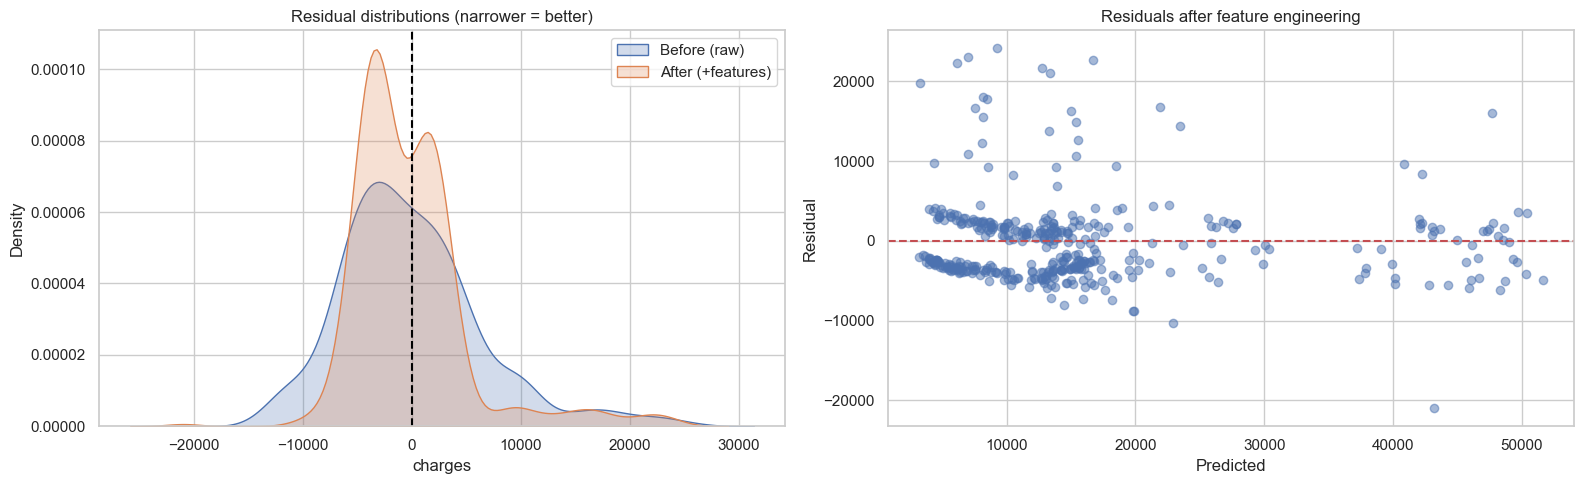

In [34]:
res_before = y_test - y_pred_lr
res_after = y_test - y_pred_fe

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.kdeplot(res_before, label="Before (raw)", fill=True, ax=axes[0])
sns.kdeplot(res_after, label="After (+features)", fill=True, ax=axes[0])
axes[0].axvline(0, color="black", linestyle="--")
axes[0].set_title("Residual distributions (narrower = better)")
axes[0].legend()

axes[1].scatter(y_pred_fe, res_after, alpha=0.5)
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Residual")
axes[1].set_title("Residuals after feature engineering")

plt.tight_layout()
plt.show()

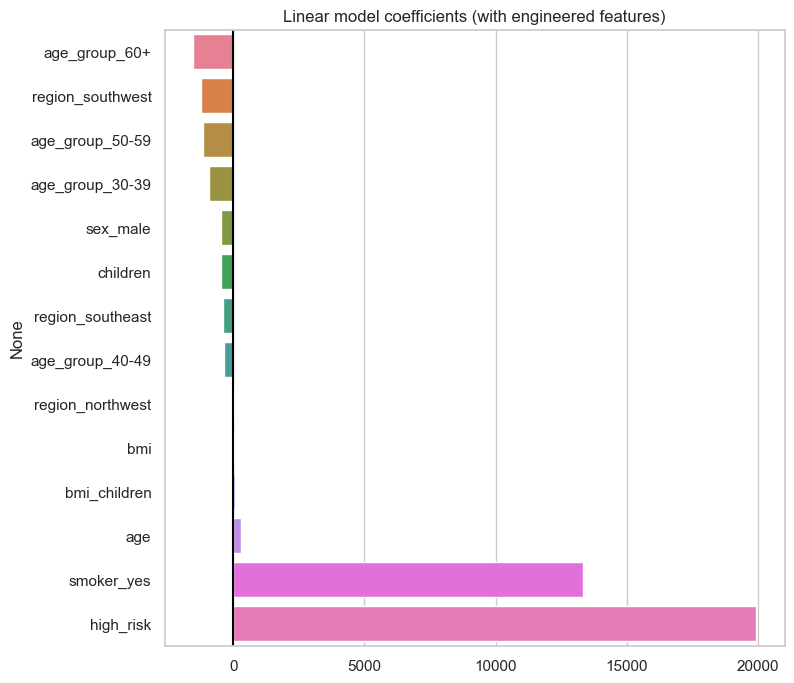

In [35]:
coefs_fe = pd.Series(lr_fe.coef_, index=X_fe.columns).sort_values()

plt.figure(figsize=(8, 8))
sns.barplot(x=coefs_fe.values, y=coefs_fe.index, hue=coefs_fe.index, legend=False)
plt.axvline(0, color="black")
plt.title("Linear model coefficients (with engineered features)")
plt.show()

## 5. Modelling with Pipeline and Grid Search

Now, let's see how using pipelines can simplify our workflow and prevent data leakage. We'll also use GridSearchCV to find the best hyperparameters.

### Task:
- Create a pipeline that includes scaling and linear regression
- Define a parameter grid for hyperparameter tuning
- Use GridSearchCV to find the best parameters and evaluate the model performance


In [36]:
X_raw = df_fe.drop(columns="charges")
X_train, X_test, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.3, random_state=42
)

num_cols = ["age", "bmi", "children", "bmi_children", "high_risk"]
cat_cols = ["sex", "smoker", "region", "age_group"]

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
])

pipe_ridge = Pipeline([
    ("prep", preprocess),
    ("model", Ridge())
])

param_grid_ridge = {"model__alpha": [0.01, 0.1, 1, 10, 100]}

grid_ridge = GridSearchCV(pipe_ridge, param_grid_ridge, cv=5, scoring="r2", n_jobs=-1)
grid_ridge.fit(X_train, y_train)

y_pred_ridge = grid_ridge.predict(X_test)
ridge_r2 = r2_score(y_test, y_pred_ridge)
ridge_rmse = np.sqrt(mean_squared_error(y_test, y_pred_ridge))

print("Best params:", grid_ridge.best_params_)
print(f"CV R2: {grid_ridge.best_score_:.4f}")
print(f"Test R2: {ridge_r2:.4f} | RMSE: {ridge_rmse:.2f}")

Best params: {'model__alpha': 1}
CV R2: 0.8021
Test R2: 0.8161 | RMSE: 5376.08


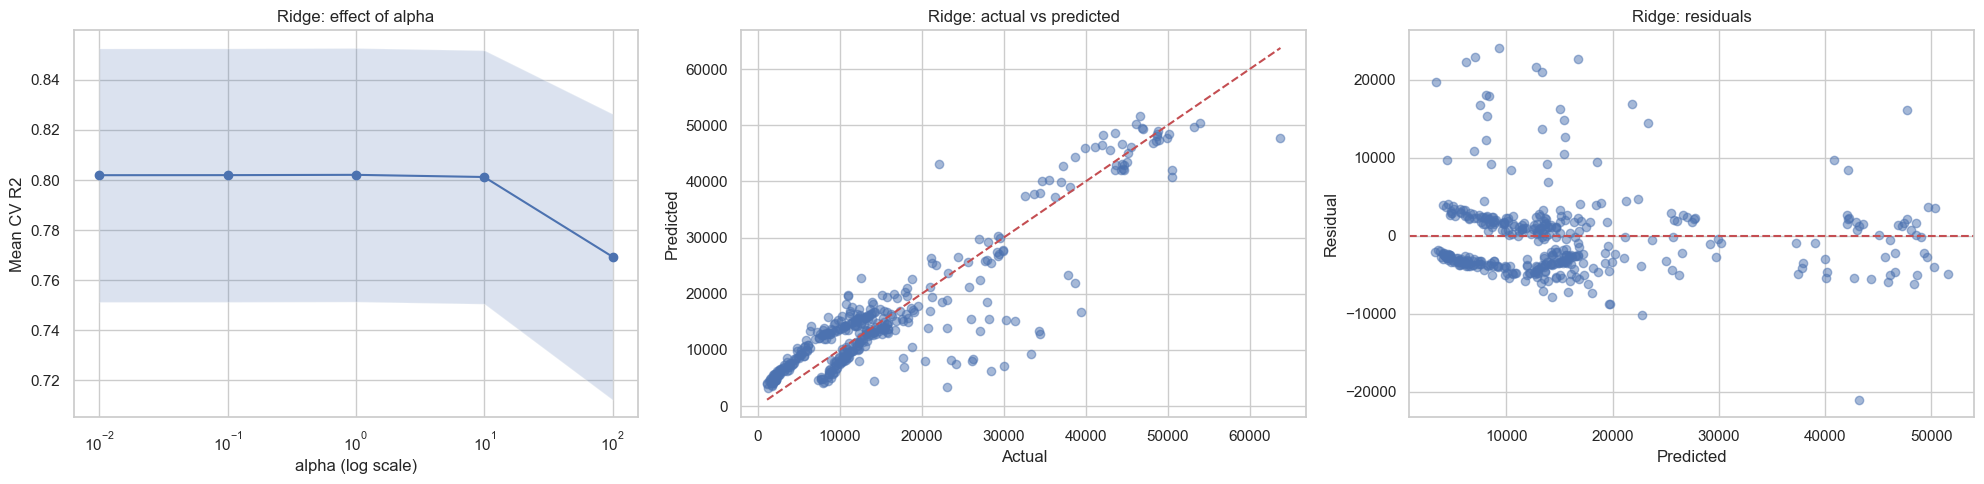

In [37]:
res = pd.DataFrame(grid_ridge.cv_results_)
alphas = res["param_model__alpha"].astype(float)

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

axes[0].semilogx(alphas, res["mean_test_score"], marker="o", label="CV (validation)")
axes[0].semilogx(alphas, res["mean_train_score"] if "mean_train_score" in res else res["mean_test_score"],
                 marker="s", linestyle="--", alpha=0.0)
axes[0].fill_between(alphas,
                     res["mean_test_score"] - res["std_test_score"],
                     res["mean_test_score"] + res["std_test_score"], alpha=0.2)
axes[0].set_xlabel("alpha (log scale)")
axes[0].set_ylabel("Mean CV R2")
axes[0].set_title("Ridge: effect of alpha")

axes[1].scatter(y_test, y_pred_ridge, alpha=0.5)
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
axes[1].set_xlabel("Actual")
axes[1].set_ylabel("Predicted")
axes[1].set_title("Ridge: actual vs predicted")

res_ridge = y_test - y_pred_ridge
axes[2].scatter(y_pred_ridge, res_ridge, alpha=0.5)
axes[2].axhline(0, color="r", linestyle="--")
axes[2].set_xlabel("Predicted")
axes[2].set_ylabel("Residual")
axes[2].set_title("Ridge: residuals")

plt.tight_layout()
plt.show()

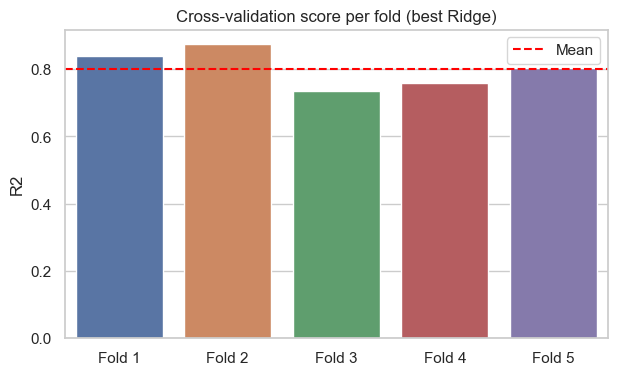

In [38]:
best_idx = grid_ridge.best_index_
fold_scores = [res.loc[best_idx, f"split{i}_test_score"] for i in range(5)]

plt.figure(figsize=(7, 4))
sns.barplot(x=[f"Fold {i+1}" for i in range(5)], y=fold_scores, hue=[f"Fold {i+1}" for i in range(5)], legend=False)
plt.axhline(np.mean(fold_scores), color="red", linestyle="--", label="Mean")
plt.ylabel("R2")
plt.title("Cross-validation score per fold (best Ridge)")
plt.legend()
plt.show()

## 6. Trying Another Model with Pipeline

Let's try using a Gradient Boosting Regressor to see if it performs better.

### Task:
- Create and use a pipeline for Gradient Boosting Regressor
- Define a parameter grid for grid search
- Use GridSearchCV to find the best parameters and evaluate the model


In [39]:
pipe_gb = Pipeline([
    ("prep", preprocess),
    ("model", GradientBoostingRegressor(random_state=42))
])

param_grid_gb = {
    "model__n_estimators": [100, 200, 300],
    "model__learning_rate": [0.01, 0.05, 0.1],
    "model__max_depth": [2, 3, 4],
    "model__subsample": [0.8, 1.0],
}

grid_gb = GridSearchCV(pipe_gb, param_grid_gb, cv=5, scoring="r2", n_jobs=-1)
grid_gb.fit(X_train, y_train)

y_pred_gb = grid_gb.predict(X_test)
gb_r2 = r2_score(y_test, y_pred_gb)
gb_rmse = np.sqrt(mean_squared_error(y_test, y_pred_gb))

print("Best params:", grid_gb.best_params_)
print(f"CV R2: {grid_gb.best_score_:.4f}")
print(f"Test R2: {gb_r2:.4f} | RMSE: {gb_rmse:.2f}")

Best params: {'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__n_estimators': 200, 'model__subsample': 1.0}
CV R2: 0.8576
Test R2: 0.8826 | RMSE: 4295.36


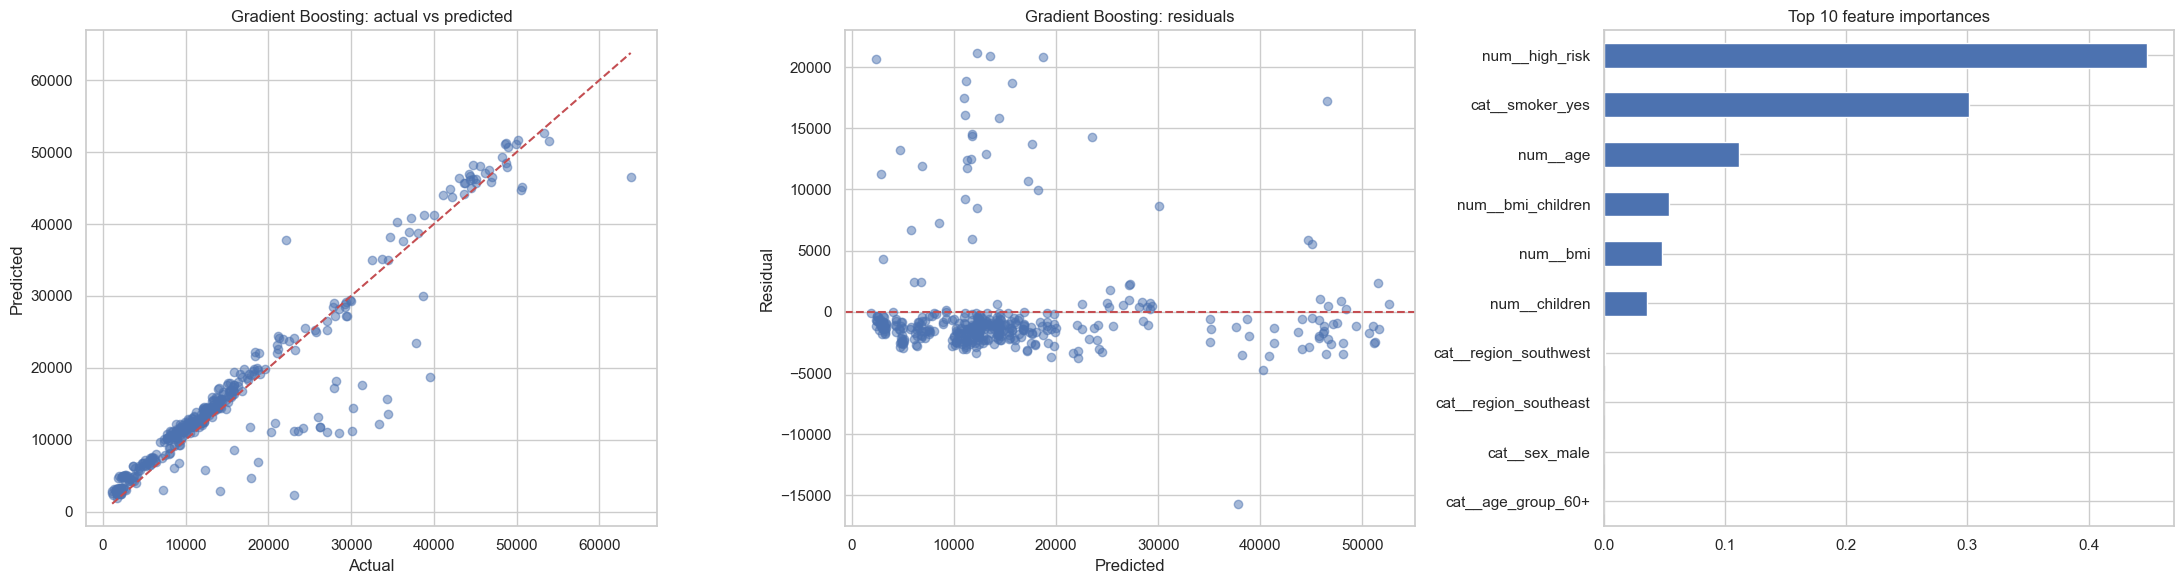

In [40]:
best_gb = grid_gb.best_estimator_
feat_names = best_gb.named_steps["prep"].get_feature_names_out()
importances = pd.Series(best_gb.named_steps["model"].feature_importances_,
                        index=feat_names).sort_values()

fig, axes = plt.subplots(1, 3, figsize=(22, 6))

axes[0].scatter(y_test, y_pred_gb, alpha=0.5)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
axes[0].set_xlabel("Actual")
axes[0].set_ylabel("Predicted")
axes[0].set_title("Gradient Boosting: actual vs predicted")

res_gb = y_test - y_pred_gb
axes[1].scatter(y_pred_gb, res_gb, alpha=0.5)
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Residual")
axes[1].set_title("Gradient Boosting: residuals")

importances.tail(10).plot(kind="barh", ax=axes[2])
axes[2].set_title("Top 10 feature importances")

plt.tight_layout()
plt.show()

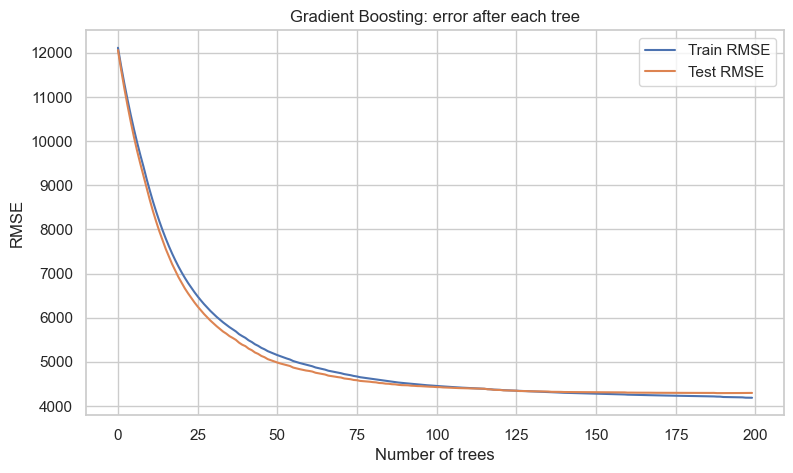

In [41]:
Xt_train = best_gb.named_steps["prep"].transform(X_train)
Xt_test = best_gb.named_steps["prep"].transform(X_test)
if hasattr(Xt_train, "toarray"):
    Xt_train, Xt_test = Xt_train.toarray(), Xt_test.toarray()

gb_model = best_gb.named_steps["model"]

train_rmse_curve = [np.sqrt(mean_squared_error(y_train, p)) for p in gb_model.staged_predict(Xt_train)]
test_rmse_curve = [np.sqrt(mean_squared_error(y_test, p)) for p in gb_model.staged_predict(Xt_test)]

plt.figure(figsize=(9, 5))
plt.plot(train_rmse_curve, label="Train RMSE")
plt.plot(test_rmse_curve, label="Test RMSE")
plt.xlabel("Number of trees")
plt.ylabel("RMSE")
plt.title("Gradient Boosting: error after each tree")
plt.legend()
plt.show()

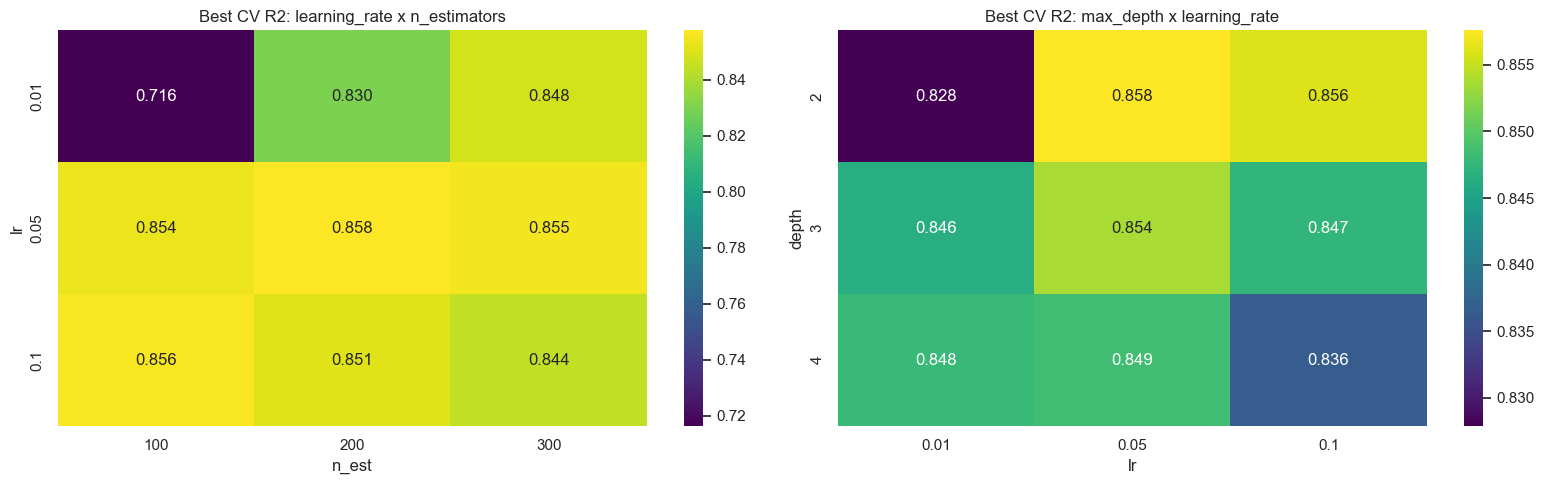

In [42]:
res_gb_grid = pd.DataFrame(grid_gb.cv_results_)
res_gb_grid["lr"] = res_gb_grid["param_model__learning_rate"].astype(float)
res_gb_grid["n_est"] = res_gb_grid["param_model__n_estimators"].astype(int)
res_gb_grid["depth"] = res_gb_grid["param_model__max_depth"].astype(int)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

pivot_lr_n = res_gb_grid.pivot_table(index="lr", columns="n_est", values="mean_test_score", aggfunc="max")
sns.heatmap(pivot_lr_n, annot=True, fmt=".3f", cmap="viridis", ax=axes[0])
axes[0].set_title("Best CV R2: learning_rate x n_estimators")

pivot_d = res_gb_grid.pivot_table(index="depth", columns="lr", values="mean_test_score", aggfunc="max")
sns.heatmap(pivot_d, annot=True, fmt=".3f", cmap="viridis", ax=axes[1])
axes[1].set_title("Best CV R2: max_depth x learning_rate")

plt.tight_layout()
plt.show()

## 7. GridSearch with Several Models

Finally, let's compare several models using GridSearchCV to find the best one.

### Task:
- Define multiple models and their parameter grids
- Use GridSearchCV to find the best model and parameters


In [43]:
models = {
    "Ridge": (
        Ridge(),
        {"model__alpha": [0.01, 0.1, 1, 10, 100]},
    ),
    "Lasso": (
        Lasso(max_iter=10000),
        {"model__alpha": [0.01, 0.1, 1, 10, 100]},
    ),
    "RandomForest": (
        RandomForestRegressor(random_state=42),
        {
            "model__n_estimators": [100, 300],
            "model__max_depth": [3, 5, 7, None],
            "model__min_samples_leaf": [1, 5, 10],
        },
    ),
    "GradientBoosting": (
        GradientBoostingRegressor(random_state=42),
        {
            "model__n_estimators": [100, 200, 300],
            "model__learning_rate": [0.01, 0.05, 0.1],
            "model__max_depth": [2, 3, 4],
            "model__subsample": [0.8, 1.0],
        },
    ),
}

results = []
fitted = {}
preds = {}

for name, (model, grid) in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    gs = GridSearchCV(pipe, grid, cv=5, scoring="r2", n_jobs=-1)
    gs.fit(X_train, y_train)
    pred = gs.predict(X_test)
    fitted[name] = gs
    preds[name] = pred
    results.append({
        "Model": name,
        "Best CV R2": gs.best_score_,
        "Test R2": r2_score(y_test, pred),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "Best params": gs.best_params_,
    })

results_df = pd.DataFrame(results).sort_values("Test R2", ascending=False)
results_df

,Model,Best CV R2,Test R2,Test RMSE,Best params
3,GradientBoosting,0.857586,0.882620,4295.358724,"{'model__learning_rate': 0.05, 'model__max_dep..."
2,RandomForest,0.845420,0.862612,4647.043211,"{'model__max_depth': 5, 'model__min_samples_le..."
1,Lasso,0.803974,0.817666,5353.479905,{'model__alpha': 100}
0,Ridge,0.802079,0.816124,5376.075966,{'model__alpha': 1}


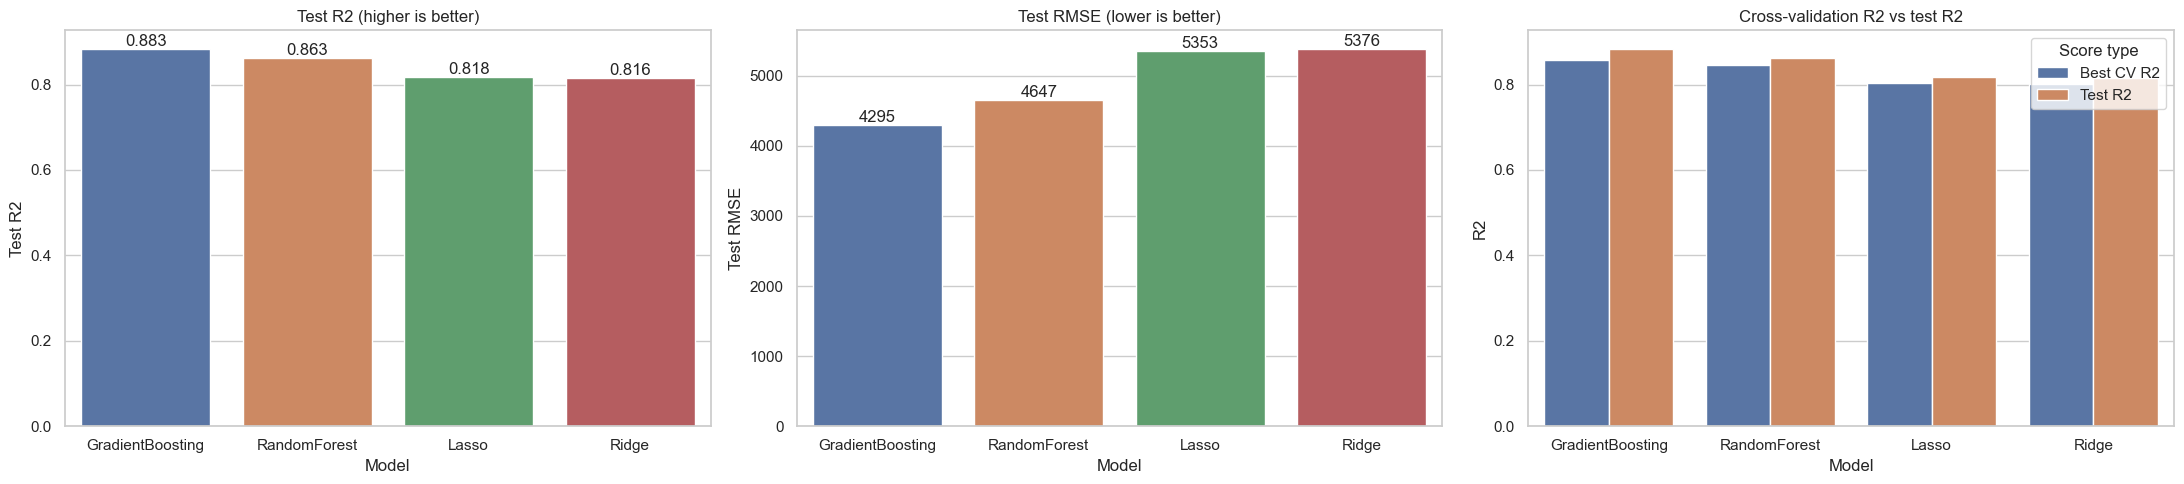

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(22, 5))

sns.barplot(data=results_df, x="Model", y="Test R2", hue="Model", legend=False, ax=axes[0])
axes[0].set_title("Test R2 (higher is better)")
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%.3f")

sns.barplot(data=results_df, x="Model", y="Test RMSE", hue="Model", legend=False, ax=axes[1])
axes[1].set_title("Test RMSE (lower is better)")
for c in axes[1].containers:
    axes[1].bar_label(c, fmt="%.0f")

melted = results_df.melt(id_vars="Model", value_vars=["Best CV R2", "Test R2"],
                         var_name="Score type", value_name="R2")
sns.barplot(data=melted, x="Model", y="R2", hue="Score type", ax=axes[2])
axes[2].set_title("Cross-validation R2 vs test R2")

plt.tight_layout()
plt.show()

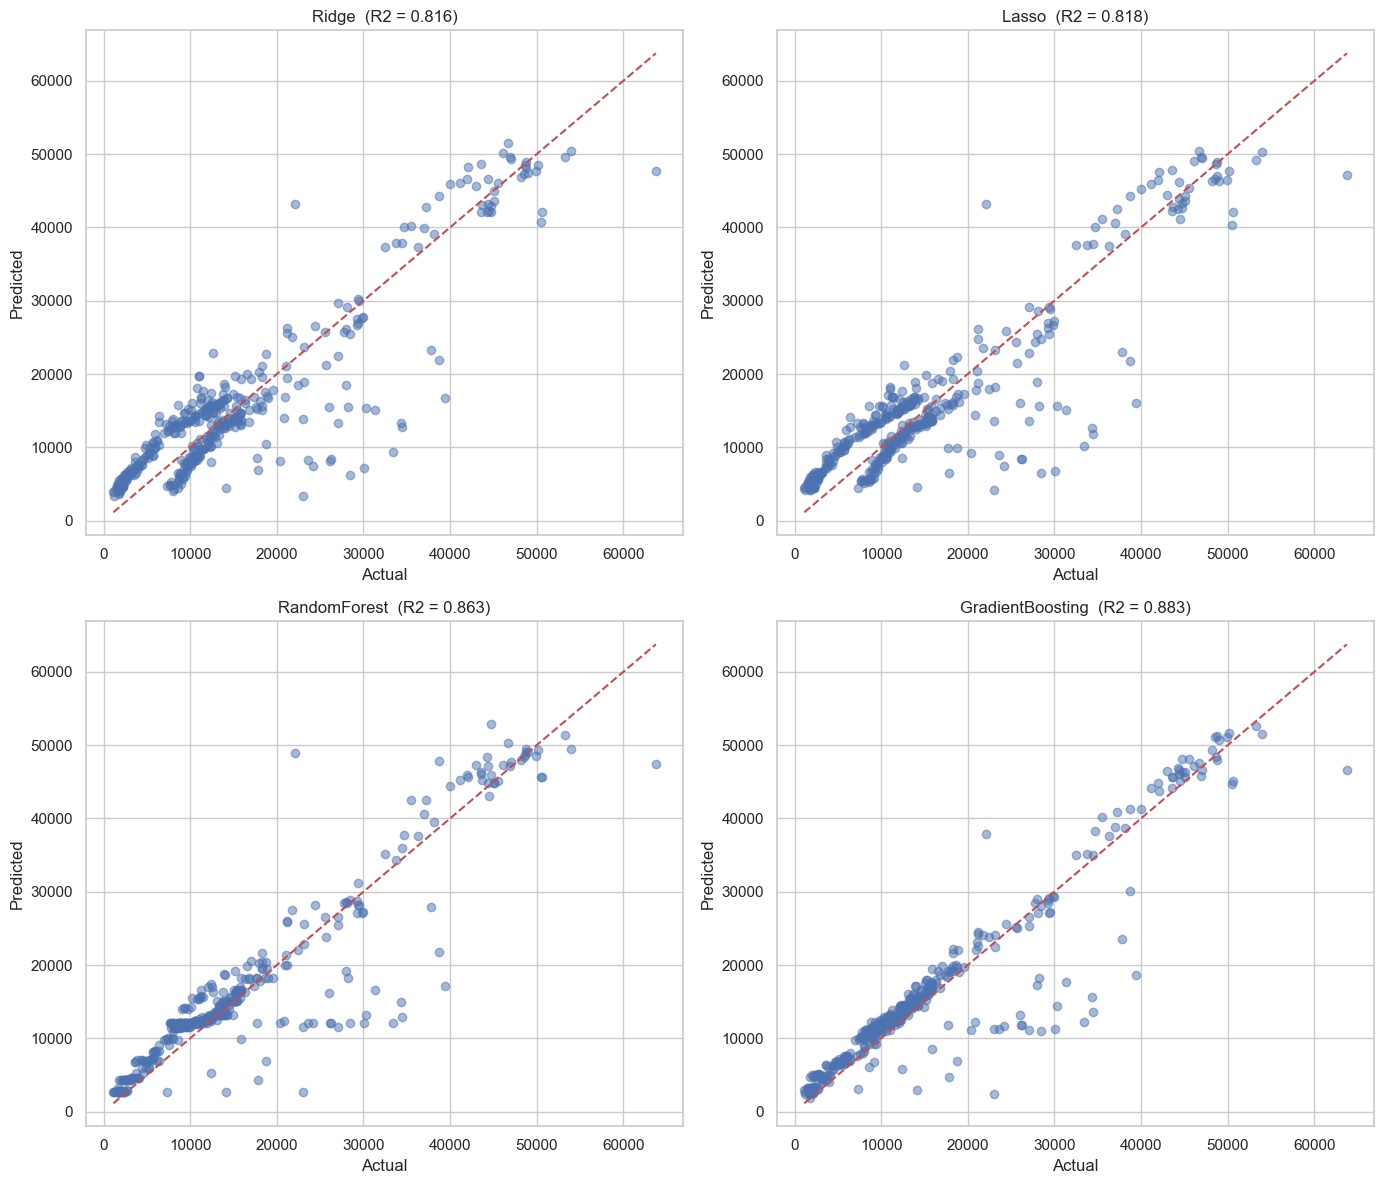

In [45]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

for ax, (name, pred) in zip(axes.ravel(), preds.items()):
    ax.scatter(y_test, pred, alpha=0.5)
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
    ax.set_title(f"{name}  (R2 = {r2_score(y_test, pred):.3f})")
    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")

plt.tight_layout()
plt.show()

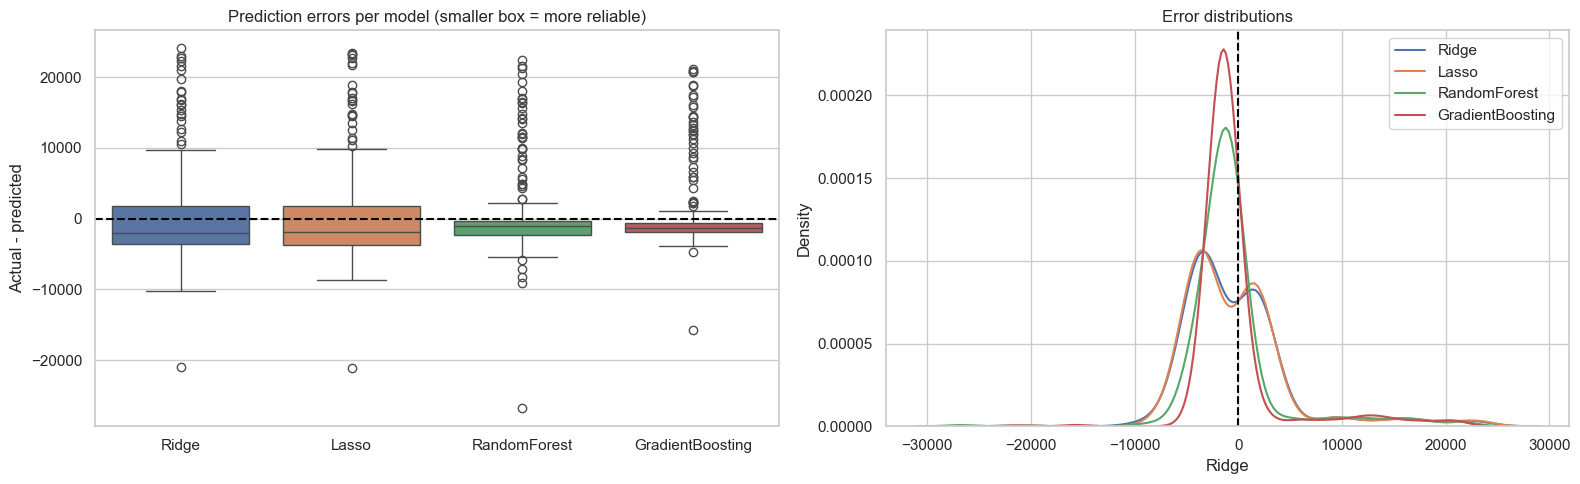

In [46]:
errors_df = pd.DataFrame({name: np.asarray(y_test) - pred for name, pred in preds.items()})

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.boxplot(data=errors_df, ax=axes[0])
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set_title("Prediction errors per model (smaller box = more reliable)")
axes[0].set_ylabel("Actual - predicted")

for name in errors_df.columns:
    sns.kdeplot(errors_df[name], label=name, ax=axes[1])
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set_title("Error distributions")
axes[1].legend()

plt.tight_layout()
plt.show()

In [47]:
best_name = results_df.iloc[0]["Model"]
best_model = fitted[best_name].best_estimator_
print("Winner:", best_name)

Winner: GradientBoosting


# Machine Learning: Master Challenge

## 8. Calculating Potential Cost or Loss

### Challenge:
Now that you've built and optimized your models, it's time for the final challenge! Your task is to minimize the Root Mean Squared Error (RMSE) of your model's predictions and calculate the potential financial impact of your model's errors.

### Task:
1. Calculate the RMSE of your final model's predictions.
2. Break down the errors into underestimation and overestimation.
3. Calculate the total potential cost or loss to the company.
4. Compete with your classmates to see who can achieve the lowest RMSE and financial impact!

### Explanation:
The RMSE provides an estimate of the average error in your model's predictions. We will also analyze the errors by categorizing them into underestimations and overestimations to understand their financial impact.

#### Steps to Calculate Underestimation and Overestimation Errors:

1. **Calculate RMSE**:
   - Use the `mean_squared_error` function from `sklearn.metrics` and pass your actual values (`y_test`) and predicted values (`y_pred_final`) to it.
   - Take the square root of the result to get the RMSE.
   
2. **Calculate Underestimation Error**:
   - Identify the instances where the actual charges (`y_test`) are greater than the predicted charges (`y_pred_final`).
   - For these instances, calculate the difference between the actual and predicted charges.
   - Sum these differences to get the total underestimation error.

3. **Calculate Overestimation Error**:
   - Identify the instances where the actual charges (`y_test`) are less than the predicted charges (`y_pred_final`).
   - For these instances, calculate the difference between the predicted and actual charges.
   - Sum these differences to get the total overestimation error.

4. **Calculate Total Potential Cost or Loss**:
   - Add the total underestimation error and the total overestimation error to get the total potential cost or loss.

### Let's see who can build the best model!

#### Detailed Instructions:

1. **Calculate RMSE**:
   - Use `mean_squared_error` with `y_test` and `y_pred_final`.
   - Use `np.sqrt` to take the square root of the result.

2. **Calculate Underestimation Error**:
   - Use a boolean condition to filter `y_test` values that are greater than `y_pred_final`.
   - Subtract the predicted values from the actual values for these instances.
   - Sum these differences.

3. **Calculate Overestimation Error**:
   - Use a boolean condition to filter `y_test` values that are less than `y_pred_final`.
   - Subtract the actual values from the predicted values for these instances.
   - Sum these differences.

4. **Calculate Total Potential Cost or Loss**:
   - Add the results of the underestimation error and overestimation error to get the total potential cost or loss.

### Example Walkthrough:

1. **Calculate RMSE**:
   - `rmse = np.sqrt(mean_squared_error(y_test, y_pred_final))`
   - This gives you the average prediction error in dollars.

2. **Calculate Underestimation Error**:
   - `underestimation_error = np.sum(y_test[y_test > y_pred_final] - y_pred_final[y_test > y_pred_final])`
   - This gives you the total amount by which the model undercharged.

3. **Calculate Overestimation Error**:
   - `overestimation_error = np.sum(y_pred_final[y_test < y_pred_final] - y_test[y_test < y_pred_final])`
   - This gives you the total amount by which the model overcharged.

4. **Calculate Total Potential Cost or Loss**:
   - `total_potential_loss = underestimation_error + overestimation_error`
   - This gives you the total financial impact of the model's errors.

### Leaderboard:
Post your RMSE score and total potential cost or loss on the class leaderboard. The student with the lowest RMSE and total potential cost or loss wins bragging rights

### Post Your Results 

- Name
- Model Type
- RMSE
- Underestimation Error
- Overestimation Error
- Total Potential Cost/Loss

In [48]:
y_pred_final = best_model.predict(X_test)

y_true = np.asarray(y_test)
y_hat = np.asarray(y_pred_final)

rmse = np.sqrt(mean_squared_error(y_true, y_hat))

under_mask = y_true > y_hat
over_mask = y_true < y_hat

underestimation_error = np.sum(y_true[under_mask] - y_hat[under_mask])
overestimation_error = np.sum(y_hat[over_mask] - y_true[over_mask])
total_potential_loss = underestimation_error + overestimation_error

print(f"Model:                  {best_name}")
print(f"RMSE:                   {rmse:,.2f}")
print(f"Underestimation error:  {underestimation_error:,.2f}  ({under_mask.sum()} customers)")
print(f"Overestimation error:   {overestimation_error:,.2f}  ({over_mask.sum()} customers)")
print(f"Total potential loss:   {total_potential_loss:,.2f}")

Model:                  GradientBoosting
RMSE:                   4,295.36
Underestimation error:  436,827.99  (56 customers)
Overestimation error:   545,750.58  (346 customers)
Total potential loss:   982,578.57


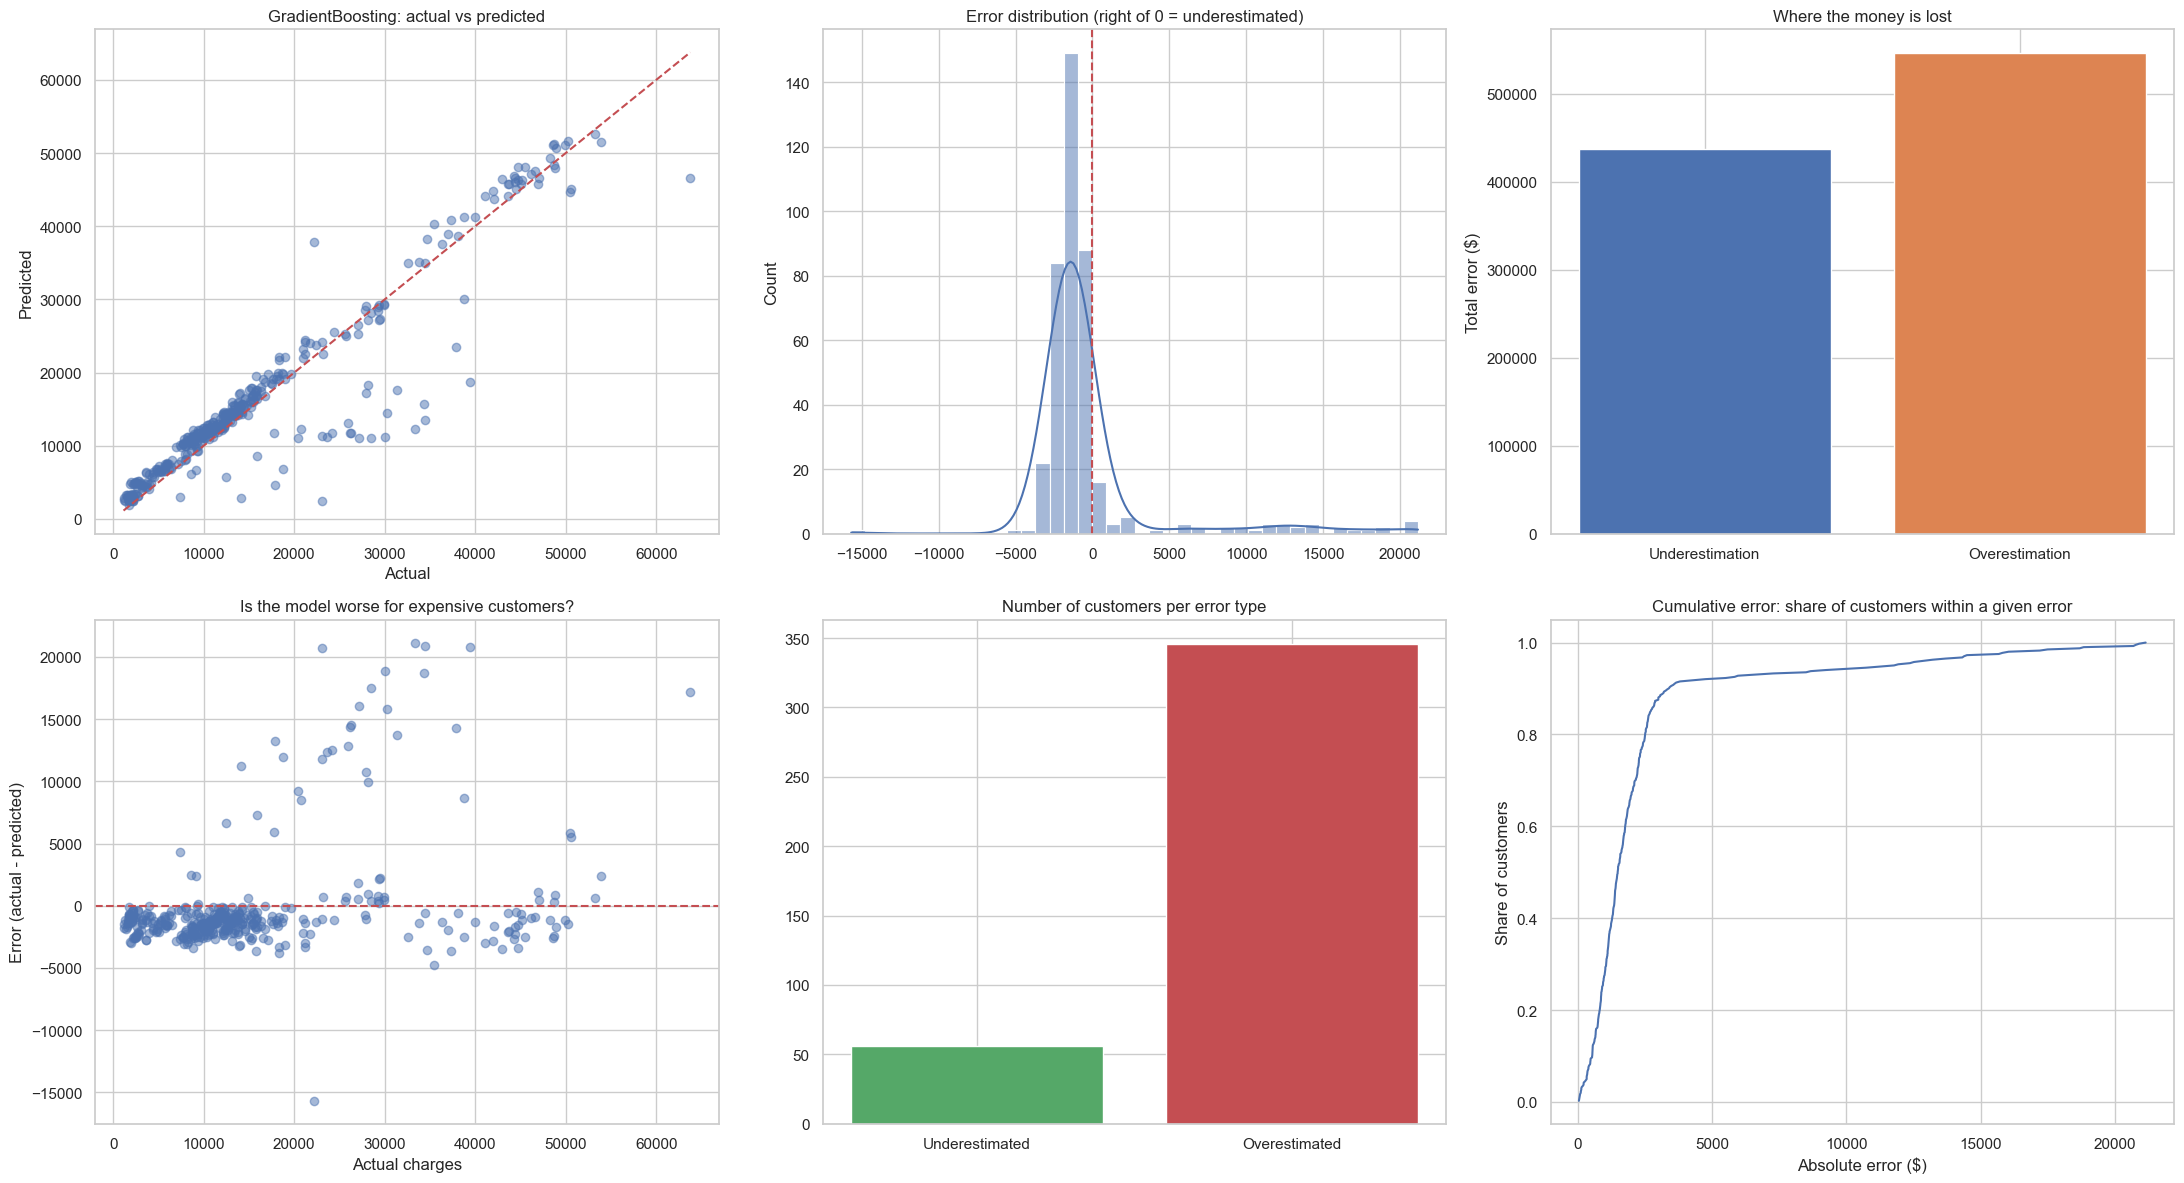

In [49]:
errors = y_true - y_hat

fig, axes = plt.subplots(2, 3, figsize=(22, 12))

axes[0, 0].scatter(y_true, y_hat, alpha=0.5)
axes[0, 0].plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], "r--")
axes[0, 0].set_xlabel("Actual")
axes[0, 0].set_ylabel("Predicted")
axes[0, 0].set_title(f"{best_name}: actual vs predicted")

sns.histplot(errors, bins=40, kde=True, ax=axes[0, 1])
axes[0, 1].axvline(0, color="r", linestyle="--")
axes[0, 1].set_title("Error distribution (right of 0 = underestimated)")

axes[0, 2].bar(["Underestimation", "Overestimation"],
               [underestimation_error, overestimation_error],
               color=sns.color_palette("deep")[:2])
axes[0, 2].set_title("Where the money is lost")
axes[0, 2].set_ylabel("Total error ($)")

axes[1, 0].scatter(y_true, errors, alpha=0.5)
axes[1, 0].axhline(0, color="r", linestyle="--")
axes[1, 0].set_xlabel("Actual charges")
axes[1, 0].set_ylabel("Error (actual - predicted)")
axes[1, 0].set_title("Is the model worse for expensive customers?")

axes[1, 1].bar(["Underestimated", "Overestimated"],
               [under_mask.sum(), over_mask.sum()],
               color=sns.color_palette("deep")[2:4])
axes[1, 1].set_title("Number of customers per error type")

sorted_abs = np.sort(np.abs(errors))
axes[1, 2].plot(sorted_abs, np.arange(1, len(sorted_abs) + 1) / len(sorted_abs))
axes[1, 2].set_xlabel("Absolute error ($)")
axes[1, 2].set_ylabel("Share of customers")
axes[1, 2].set_title("Cumulative error: share of customers within a given error")

plt.tight_layout()
plt.show()

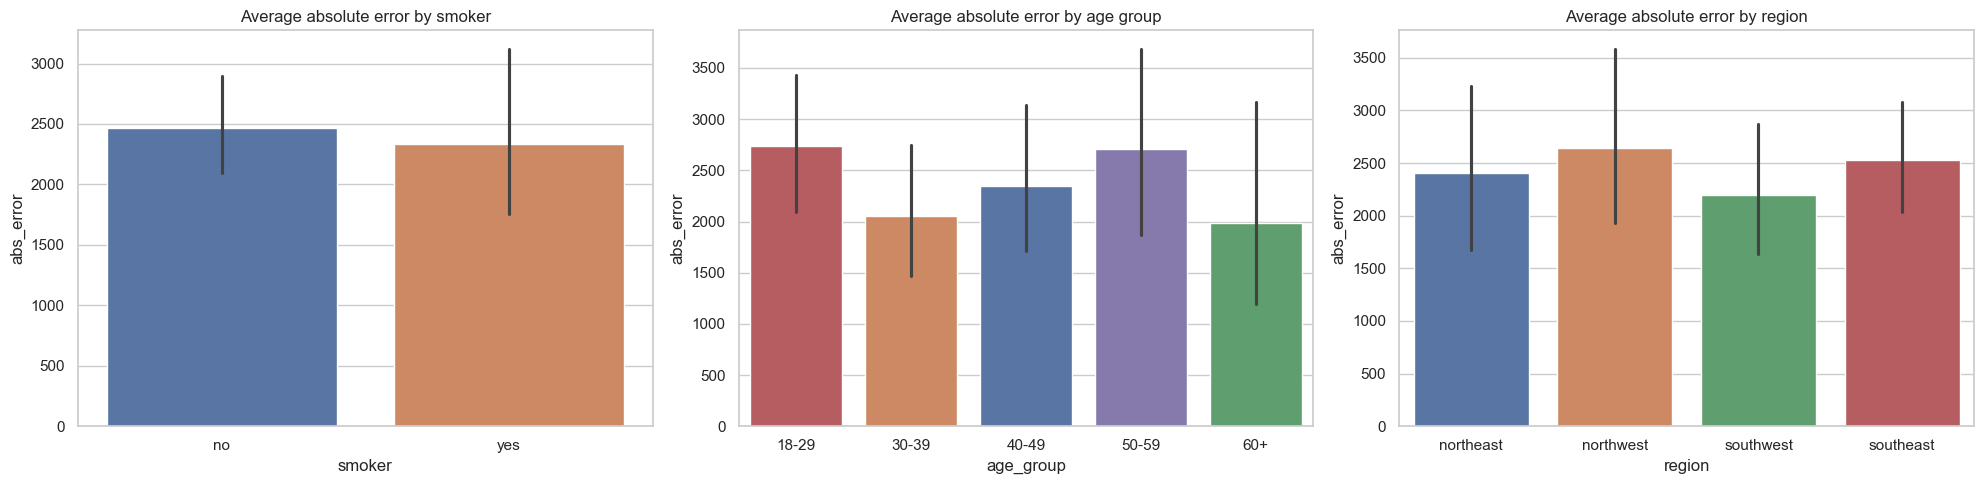

In [50]:
err_df = pd.DataFrame({
    "error": errors,
    "abs_error": np.abs(errors),
    "smoker": X_test["smoker"].values,
    "region": X_test["region"].values,
    "age_group": X_test["age_group"].values,
})

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

sns.barplot(data=err_df, x="smoker", y="abs_error", hue="smoker", legend=False, ax=axes[0])
axes[0].set_title("Average absolute error by smoker")

sns.barplot(data=err_df, x="age_group", y="abs_error",
            order=["18-29", "30-39", "40-49", "50-59", "60+"],
            hue="age_group", legend=False, ax=axes[1])
axes[1].set_title("Average absolute error by age group")

sns.barplot(data=err_df, x="region", y="abs_error", hue="region", legend=False, ax=axes[2])
axes[2].set_title("Average absolute error by region")

plt.tight_layout()
plt.show()

## Conclusion

Congratulations! You've completed the lab. Here's a summary of what we've covered:
1. Established a naive baseline using the mean of the target variable.
2. Built an initial linear regression model without any feature engineering or optimization.
3. Performed feature engineering to create new, potentially useful features.
4. Used pipelines and GridSearchCV to optimize the model.
5. Evaluated the final model's performance using RMSE to understand its business impact.

By following these steps, you now have a robust understanding of how to approach a regression problem, from initial exploration to model optimization and business impact assessment. Great job!


1. Baseline: predicting the average price gives an R² of about 0, so any real model must beat that.
2. Plain linear regression captured the main trends but not the interactions.
3. Feature engineering, especially the high_risk flag, gave the linear model the smoker x BMI interaction it couldn’t learn alone.
4. Pipelines and GridSearchCV prevented data leakage and tuned hyperparameters properly.
5. Tree-based models learn interactions on their own, which is why they typically win on this kind of data.
6. RMSE and the under/over split turn the model’s quality into money, which is what the business cares about.